# STREAM conventional thymic T-cell trajectories (12w and 17w)

This notebook follows the STREAM method applied in Chevalier et al. You can see each stage of trajectory construction in the notebook, and the same figures are saved as PNG files.

Since the Park et al. used conventional T-cell labels we also used eight exact conventional T-cell labels, **1,650 proportionally sampled cells per week for limitation in computational resources**, independent 12w and 17w STREAM models. 

**Run cells from top to bottom.** Although every function comes from STREAM trajectory inference notebook, GPT-6 is used to put them into functions to assure this notebook can be run for any week or similar selection.

## 1. Notebook display and settings

Turn on inline Matplotlib output and set the input folders, T-cell labels, sampling size, and marker genes. 

In [1]:
%matplotlib inline # Show Matplotlib figures below each cell.

UsageError: unrecognized arguments: # Show Matplotlib figures below each cell.


In [2]:
# Load the libraries and tools used throughout the notebook.
from pathlib import Path
import ast
import gc
import json
import re
import unicodedata
import warnings

from IPython.display import display
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import stream as st

import inspect
import matplotlib.cbook as cbook
from numbers import Number

# Below is to fix matplotlib and networkx version differences. Obtained using GPT-6.

if not hasattr(nx.Graph, 'node'):
    nx.Graph.node = property(lambda graph: graph._node)
if not hasattr(nx.Graph, 'edge'):
    nx.Graph.edge = property(lambda graph: graph._adj)
if 'random_state' not in inspect.signature(nx.spring_layout).parameters:
    _networkx_spring_layout = nx.spring_layout
    def stream_spring_layout(graph, *args, **kwargs):
        if 'random_state' in kwargs:
            kwargs['seed'] = kwargs.pop('random_state')
        return _networkx_spring_layout(graph, *args, **kwargs)
    nx.spring_layout = stream_spring_layout

if not hasattr(cbook, 'iterable'):
    def _stream_iterable(value):
        try:
            iter(value)
            return True
        except TypeError:
            return False
    cbook.iterable = _stream_iterable
if not hasattr(cbook, 'is_numlike'):
    cbook.is_numlike = lambda value: isinstance(value, Number)

INPUT_DIR = Path('../Results/Data_prep_outputs').resolve()
OUTPUT_ROOT = Path('../Results/STREAM_outputs').resolve()
WEEKS = ('12w', '17w')

# Exact labels from the prepared Park et al. thymus annotations.
KNOWN_T_CELL_TYPES = [
    'CD4+T', 'CD8+T', 'CD8αα(I)', 'CD8αα(II)',
    'DN(P)', 'DN(Q)', 'DN(early)', 'DP(P)', 'DP(Q)',
    'NKT', 'T(agonist)', 'Th17', 'Treg', 'Treg(diff)',
    'αβT(entry)', 'γδT'
]

# Figure 2 conventional alpha-beta T-cell differentiation states only.
CONVENTIONAL_CELL_TYPES = [
    'DN(early)', 'DN(P)', 'DN(Q)',
    'DP(P)', 'DP(Q)', 'αβT(entry)',
    'CD4+T', 'CD8+T'
]
assert len(KNOWN_T_CELL_TYPES) == 16 and len(set(KNOWN_T_CELL_TYPES)) == 16
assert set(CONVENTIONAL_CELL_TYPES).issubset(KNOWN_T_CELL_TYPES)

TARGET_CELLS_PER_WEEK = 1650
SAMPLING_SEED = 42
GENE_EXPR_CUTOFF = 1.0
RUN_GENE_TESTS = False  # Transition / differential / leaf genes can take time which was present in original STREAM.ipynb.
STREAM_N_JOBS = 4  # only for STREAM's variable-gene selection

# Genes discussed in Park et al. Fig. 2 and main text. Only detected genes are plotted.
T_CELL_MARKERS = [
    'CD34', 'CD7', 'CD1A', 'ST18', 'PTCRA', 'CDK1', 'MKI67',
    'RAG1', 'RAG2', 'AQP3', 'CCR9', 'TOX2', 'CD4', 'CD8A', 'CD8B'
]

for week in WEEKS:
    for name in ('expression', 'cell_label', 'cell_label_color'):
        path = INPUT_DIR / f'{week}_{name}.tsv.gz'
        if not path.is_file():
            raise FileNotFoundError(f'Missing {week} STREAM input: {path.resolve()}')

OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
print('STREAM version:', st.__version__)
print('Conventional T-cell labels:', CONVENTIONAL_CELL_TYPES)
print('Input directory:', INPUT_DIR.resolve())
print('Output directory:', OUTPUT_ROOT.resolve())
# Legacy STREAM joins file_path + file_name literally; include the trailing slash.
STREAM_INPUT_PATH = str(INPUT_DIR) + '/'
print('STREAM input path:', STREAM_INPUT_PATH)

print('Stratified conventional cells per week:', TARGET_CELLS_PER_WEEK)
print('Sampling seed:', SAMPLING_SEED)

STREAM version: 0.3.1
Conventional T-cell labels: ['DN(early)', 'DN(P)', 'DN(Q)', 'DP(P)', 'DP(Q)', 'αβT(entry)', 'CD4+T', 'CD8+T']
Input directory: /home/eren/Eren_run/Case_study_2/Results/Data_prep_outputs
Output directory: /home/eren/Eren_run/Case_study_2/Results/STREAM_outputs
STREAM input path: /home/eren/Eren_run/Case_study_2/Results/Data_prep_outputs/
Stratified conventional cells per week: 1650
Sampling seed: 42


/home/eren/miniforge3/envs/env_stream_03/lib/python3.6/site-packages/rpy2/robjects/pandas2ri.py:14: FutureWarning: pandas.core.index is deprecated and will be removed in a future version.  The public classes are available in the top-level namespace.
  from pandas.core.index import Index as PandasIndex


## 2. Select and sample conventional T cells

Use exact cell-type names and sample each group in proportion to its abundance. This creates a reproducible total of exactly **1,650 cells per week**.

In [3]:
def root_stage_labels(labels):
    # Only the earliest annotated conventional thymocytes inform root selection to get better trajectories.
    early = ['DN(early)'] if 'DN(early)' in set(labels) else []
    if not early:
        raise ValueError('DN(early) is absent; root cannot be assigned from the requested early stage.')
    return early

def stratified_sample_ids(labels, target, seed):
    # Preserves the original proportions and exact total.
    counts = labels.value_counts().sort_index()
    total = int(counts.sum())
    if target <= 0 or target > total:
        raise ValueError('Sampling target must be between 1 and the input cell count.')

    expected = counts.astype(float) * (float(target) / float(total))
    allocation = np.floor(expected).astype(int)
    leftover = target - int(allocation.sum())
    # Tie handling for reproducibility.
    order = (expected - allocation).sort_values(ascending=False, kind='mergesort').index
    allocation.loc[order[:leftover]] += 1
    if (allocation > counts).any() or allocation.sum() != target:
        raise AssertionError('Invalid per-cell-type sampling quotas.')

    random = np.random.RandomState(seed)
    chosen = []
    for label in counts.index:
        n = int(allocation.loc[label])
        pool = labels.index[labels == label].to_numpy()
        if n:
            chosen.extend(random.choice(pool, size=n, replace=False).tolist())
    random.shuffle(chosen)

    audit = pd.DataFrame({
        'label': counts.index,
        'original_n_cells': counts.values.astype(int),
        'original_pct': (counts.values / float(total) * 100),
        'expected_n_cells': expected.values,
        'sampled_n_cells': allocation.values.astype(int),
        'sampled_pct': allocation.values / float(target) * 100,
    })
    if len(chosen) != target or len(set(chosen)) != target:
        raise AssertionError('Stratified sampling did not select exactly the required unique cells.')
    return chosen, audit

## Save and show STREAM plots

Every generated Matplotlib figure is **saved to the week’s `figures/` folder and displayed below the cell**. Optional plot failures produce a warning; essential gene-filtering errors still stop execution.

In [4]:
def save_plot(figures_dir, name, plotting_fn, *args, **kwargs):
    essential = name in ('01_gene_filtering', '02_variable_genes')
    plt.close('all')  # Do not mix figures from separate steps.
    try:
        result = plotting_fn(*args, **kwargs)
        figures = [plt.figure(n) for n in plt.get_fignums()]
        if not figures and isinstance(result, plt.Figure):
            figures = [result]
        if not figures:
            print(f'No open Matplotlib figure for {name}.')
        for i, fig in enumerate(figures, start=1):
            suffix = '' if len(figures) == 1 else f'_{i:02d}'
            fig.savefig(figures_dir / f'{name}{suffix}.png',
                        dpi=200, bbox_inches='tight')
            display(fig) 
        return result
    except Exception as error:
        if essential:
            raise  #Gene selection failures must stop the run.
        message = f'{name}: {type(error).__name__}: {error}'
        warnings.warn('Optional plot skipped: ' + message)
        (figures_dir / f'{name}_error.txt').write_text(message + '\n')
        return None
    finally:
        plt.close('all')  #Avoid showing the same figure twice.

## 4. Read fitted branches and select the root

Work out where each cell falls along the fitted tree, measure its distances to each STREAM state, and find the root closest to DN(early) cells.

In [5]:
def parse_branch_id(value):
    #Convert a stored branch identifier to its two endpoints
    if isinstance(value, str):
        value = ast.literal_eval(value)
    if isinstance(value, (tuple, list, np.ndarray)) and len(value) == 2:
        return tuple(value)
    raise ValueError(f'Unexpected STREAM branch identifier: {value!r}')


def tree_geometry(adata):
    #Read the fitted tree, its state labels, and branch lengths.
    if 'flat_tree' not in adata.uns:
        raise KeyError('STREAM flat_tree is missing. Run graph fitting and extension first.')
    graph = adata.uns['flat_tree']
    node_to_state = {n: str(attrs.get('label', n)) for n, attrs in graph.nodes(data=True)}
    state_to_node = {state: node for node, state in node_to_state.items()}
    if len(state_to_node) != len(node_to_state):
        raise ValueError('Duplicate STREAM state labels in flat_tree')
    if not nx.is_tree(graph):
        raise ValueError('Expected a connected tree from STREAM')
    branches, edges = {}, []
    for u, v, attrs in graph.edges(data=True):
        branch_id = parse_branch_id(attrs.get('id', (u, v)))
        if set(branch_id) != {u, v}:
            raise ValueError(f'Branch {branch_id} does not match tree edge {(u, v)}')
        length = float(attrs.get('len', attrs.get('length', np.nan)))
        if not np.isfinite(length) or length <= 0:
            raise ValueError(f'Invalid edge length for {(u, v)}')
        branches[branch_id] = (branch_id[0], branch_id[1], length)
        branches[branch_id[::-1]] = (branch_id[1], branch_id[0], length)
        edges.append({'from_state': node_to_state[u], 'to_state': node_to_state[v],
                      'branch_id': str(branch_id), 'branch_length': length})
    return graph, node_to_state, state_to_node, branches, edges


def cell_state_distances(adata, graph, state_to_node, branches):
   #Find the shortest tree distance from each cell to every state.
    required = {'branch_id', 'branch_lam'}
    if not required.issubset(adata.obs.columns):
        raise KeyError(f'Missing STREAM projection columns: {required - set(adata.obs.columns)}')
    shortest = {
        state: nx.single_source_dijkstra_path_length(graph, node, weight='len')
        for state, node in state_to_node.items()
    }
    records = []
    for cell_id, row in adata.obs.iterrows():
        branch_id = parse_branch_id(row['branch_id'])
        if branch_id not in branches:
            raise KeyError(f'Unknown branch for cell {cell_id}: {branch_id}')
        u, v, length = branches[branch_id]
        lam = float(row['branch_lam'])
        tol = max(1e-6, 1e-4 * length)
        if not np.isfinite(lam) or not (-tol <= lam <= length + tol):
            raise ValueError(f'Invalid projected position for {cell_id}: {lam}')
        lam = np.clip(lam, 0.0, length)
        result = {'cell_id': str(cell_id), 'branch_id': str(branch_id),
                  'branch_from': str(graph.nodes[u].get('label', u)),
                  'branch_to': str(graph.nodes[v].get('label', v)),
                  'branch_lam': lam, 'branch_length': length}
        for state in sorted(state_to_node):
            result['distance_to_' + state] = min(
                lam + shortest[state][u], length - lam + shortest[state][v]
            )
        records.append(result)
    return pd.DataFrame.from_records(records)


def infer_root(adata, distances, states):
    #Choose the state nearest to DN(early) cells by median distance.
    early = root_stage_labels(adata.obs['label'].astype(str).unique())
    early_mask = adata.obs['label'].astype(str).isin(early)
    early_ids = adata.obs_names[early_mask].astype(str)
    early_distances = distances.set_index('cell_id').loc[
        early_ids, ['distance_to_' + state for state in sorted(states)]
    ]
    medians = early_distances.median(axis=0)
    means = early_distances.mean(axis=0)
    candidates = pd.DataFrame({
        'state': [column.replace('distance_to_', '', 1) for column in medians.index],
        'median_distance_to_DN_early': medians.values,
        'mean_distance_to_DN_early': means.values,
        'n_DN_early_cells': len(early_ids)
    }).sort_values('median_distance_to_DN_early').reset_index(drop=True)
    root = str(candidates.iloc[0]['state'])
    print('Root {} chosen from {} DN(early) cells ONLY.'.format(root, len(early_ids)))
    print('Closest candidate states for DN(early):')
    print(candidates.head(5).to_string(index=False))
    return root, early, candidates

## Validation tables and figures

After fitting, summarize pseudotime by cell type, show the makeup of each branch, and plot available T-cell-marker expression. 

In [6]:
def export_biological_validation(adata, cell_distances, tables_dir, figures_dir, week):
    #Export post-fit stage, branch, and marker checks.
    # These are post-fit diagnostics, not constraints used by STREAM.
    labels = CONVENTIONAL_CELL_TYPES
    data = cell_distances[['cell_id', 'label', 'pseudotime_from_root',
                           'branch_from', 'branch_to']].copy()
    data['label'] = data['label'].astype(str)
    data['branch_pair'] = [
        '--'.join(sorted([str(u), str(v)])) for u, v in
        zip(data['branch_from'], data['branch_to'])
    ]

    summaries = []
    for stage in labels:
        times = data.loc[data['label'] == stage, 'pseudotime_from_root'].dropna()
        summaries.append({
            'cell_type': stage,
            'developmental_order_for_diagnostic': labels.index(stage),
            'n_cells': int(len(times)),
            'median_pseudotime': float(times.median()) if len(times) else np.nan,
            'q25_pseudotime': float(times.quantile(0.25)) if len(times) else np.nan,
            'q75_pseudotime': float(times.quantile(0.75)) if len(times) else np.nan,
        })
    stages = pd.DataFrame(summaries)
    stages.to_csv(tables_dir / 'pseudotime_by_cell_type.csv', index=False)

    counts = pd.crosstab(data['branch_pair'], data['label']).reindex(
        columns=labels, fill_value=0)
    counts.to_csv(tables_dir / 'branch_cell_type_counts.csv')
    counts.div(counts.sum(axis=1).replace(0, np.nan), axis=0).mul(100).to_csv(
        tables_dir / 'branch_cell_type_row_pct.csv')
    counts.div(counts.sum(axis=0).replace(0, np.nan), axis=1).mul(100).to_csv(
        tables_dir / 'cell_type_distribution_across_branches_pct.csv')

    # A simple descriptive check; mature CD4+ and CD8+ are parallel, not sequential.
    stage_groups = [
        ('DN(early)',), ('DN(P)',), ('DN(Q)',), ('DP(P)',),
        ('DP(Q)',), ('αβT(entry)',), ('CD4+T', 'CD8+T')
    ]
    group_medians = []
    for group in stage_groups:
        group_values = data.loc[data['label'].isin(group), 'pseudotime_from_root']
        group_medians.append(float(group_values.median()))
    inversions = []
    for i in range(len(stage_groups) - 1):
        if group_medians[i + 1] < group_medians[i]:
            inversions.append('{} > {}'.format('/'.join(stage_groups[i]),
                                               '/'.join(stage_groups[i + 1])))
    diagnostic = {
        'week': week,
        'rooted_from': 'DN(early) only',
        'stage_order_descriptive_inversions': inversions,
        'note': 'Median ordering is descriptive; non-monotonic medians and branching require biological review. No trajectory constraints applied.'
    }
    (tables_dir / 'biological_validation_summary.json').write_text(
        json.dumps(diagnostic, indent=2, ensure_ascii=False), encoding='utf-8')
    print('\nPseudotime by annotated developmental stage:')
    print(stages.to_string(index=False))
    if inversions:
        print('Potential departures from expected stage order:', inversions)
    else:
        print('Stage medians have no adjacent inversions; inspect distributions and markers.')
    print('\nCell-type proportions within STREAM branches (%):')
    print(counts.div(counts.sum(axis=1), axis=0).mul(100).round(1).to_string())

    try:
        fig, ax = plt.subplots(figsize=(11, 5))
        groups = [data.loc[data['label'] == label, 'pseudotime_from_root'].dropna().values
                  for label in labels]
        ax.boxplot(groups, showfliers=False)
        ax.set_xticklabels(labels, rotation=35, ha='right')
        ax.set_ylabel('Pseudotime from DN(early)-inferred root')
        ax.set_title('{}: developmental labels along inferred pseudotime'.format(week))
        fig.tight_layout()
        fig.savefig(figures_dir / '18_pseudotime_by_cell_type.png', dpi=200,
                    bbox_inches='tight')
        display(fig)  # Show the saved figure in Jupyter.
        plt.close(fig)

        row_pct = counts.div(counts.sum(axis=1), axis=0).mul(100).fillna(0)
        fig, ax = plt.subplots(figsize=(11, max(3.5, len(counts) * 0.50)))
        im = ax.imshow(row_pct.values, aspect='auto', cmap='Blues', vmin=0, vmax=100)
        ax.set_xticks(range(len(labels)))
        ax.set_xticklabels(labels, rotation=35, ha='right')
        ax.set_yticks(range(len(counts)))
        ax.set_yticklabels(counts.index.tolist())
        ax.set_xlabel('Annotated conventional T-cell type')
        ax.set_ylabel('Fitted STREAM branch')
        ax.set_title('{}: cell-type composition within branches (%)'.format(week))
        fig.colorbar(im, ax=ax, label='% of cells on branch')
        fig.tight_layout()
        fig.savefig(figures_dir / '19_branch_cell_type_heatmap.png', dpi=200,
                    bbox_inches='tight')
        display(fig)  # Show the saved figure in Jupyter.
        plt.close(fig)
    except Exception as error:
        plt.close('all')
        warnings.warn('Biological validation visualization failed (tables saved): {}'.format(error))

    # Marker expression profiles: plot from the existing normalized data only.
    # Selected variable genes still come from STREAM, not these marker lists.
    available_markers = [g for g in T_CELL_MARKERS if g in adata.var_names]
    if available_markers:
        marker_matrix = adata[:, available_markers].X
        if hasattr(marker_matrix, 'toarray'):
            marker_matrix = marker_matrix.toarray()
        marker_values = pd.DataFrame(np.asarray(marker_matrix),
                                     index=adata.obs_names.astype(str),
                                     columns=available_markers)
        marker_values = marker_values.loc[data['cell_id'].values].reset_index(drop=True)
        ranks = data['pseudotime_from_root'].rank(method='first')
        bins = pd.qcut(ranks, 10, labels=False)
        marker_values['pseudotime_decile'] = bins.values.astype(int) + 1
        marker_values['pseudotime_from_root'] = data['pseudotime_from_root'].values
        marker_values.to_csv(tables_dir / 'marker_expression_per_cell.csv', index=False)
        means = marker_values.groupby('pseudotime_decile').mean()
        means.to_csv(tables_dir / 'marker_means_by_pseudotime_decile.csv')
        marker_groups = [
            ('early_and_recombination', ['CD34', 'CD7', 'CD1A', 'ST18', 'PTCRA', 'RAG1', 'RAG2']),
            ('proliferation_and_transition', ['CDK1', 'MKI67', 'AQP3', 'CCR9', 'TOX2']),
            ('lineage_maturation', ['CD4', 'CD8A', 'CD8B'])
        ]
        try:
            for suffix, gene_names in marker_groups:
                gene_names = [g for g in gene_names if g in means.columns]
                if not gene_names:
                    continue
                fig, ax = plt.subplots(figsize=(8, 4.5))
                for gene in gene_names:
                    ax.plot(means.index, means[gene], marker='o', label=gene)
                ax.set_xlabel('Pseudotime decile (DN(early) root)')
                ax.set_ylabel('Mean input expression (unchanged normalization)')
                ax.set_title('{}: {}'.format(week, suffix.replace('_', ' ')))
                ax.legend(loc='best', fontsize=9)
                fig.tight_layout()
                fig.savefig(figures_dir / '20_marker_{}.png'.format(suffix),
                            dpi=200, bbox_inches='tight')
                display(fig)  # Show the saved figure in Jupyter.
                plt.close(fig)
        except Exception as error:
            plt.close('all')
            warnings.warn('Marker trend visualization failed (tables saved): {}'.format(error))
    return diagnostic

## Run one week in small steps

The following functions prepare one week, filter its genes, choose a root, visualize markers, run optional gene tests, and export all results. The main sections below call them step by step.

### 6A. Read, select, and sample cells

Read one week’s normalized input, keep only the eight conventional labels, and sample exactly 1,650 cells. Save a list of the selected cells.

In [7]:
def prepare_week(week):
    #Read, select, and proportionally sample this week's T cells.
    print(f'\n{"=" * 24}  {week}  {"=" * 24}')
    out_dir = OUTPUT_ROOT / week
    figures_dir = out_dir / 'figures'
    tables_dir = out_dir / 'tables'
    for directory in (out_dir, figures_dir, tables_dir):
        directory.mkdir(parents=True, exist_ok=True)

    # This week's expression and metadata are never concatenated with another week.
    # Legacy STREAM concatenates file_path + file_name, rather than joining paths.
    # Passing an absolute filename here can remove the first '/', so use basenames.
    expression_file = f'{week}_expression.tsv.gz'
    labels_file = f'{week}_cell_label.tsv.gz'
    colors_file = f'{week}_cell_label_color.tsv.gz'
    for basename in (expression_file, labels_file, colors_file):
        expected = INPUT_DIR / basename
        if not expected.is_file():
            raise FileNotFoundError(str(expected))
    print('Reading:', STREAM_INPUT_PATH + expression_file)
    adata = st.read(
        file_path=STREAM_INPUT_PATH,
        file_name=expression_file,
        file_format='tsv',
        workdir=str(out_dir.resolve())
    )
    st.add_cell_labels(adata, file_path=STREAM_INPUT_PATH, file_name=labels_file)
    st.add_cell_colors(adata, file_path=STREAM_INPUT_PATH, file_name=colors_file)
    if 'label' not in adata.obs:
        raise KeyError('st.add_cell_labels did not create adata.obs["label"].')

    input_labels = adata.obs['label'].astype(str)
    n_input_cells = int(adata.n_obs)
    print('Prepared input:', adata.shape)
    unexpected = sorted(set(input_labels.unique()) - set(KNOWN_T_CELL_TYPES))
    if unexpected:
        raise ValueError('Unknown cell types in the prepared input: ' + repr(unexpected))

    selection_audit = pd.DataFrame({
        'label': KNOWN_T_CELL_TYPES,
        'n_cells': input_labels.value_counts().reindex(KNOWN_T_CELL_TYPES, fill_value=0).values,
        'included_in_conventional_trajectory': [
            label in CONVENTIONAL_CELL_TYPES for label in KNOWN_T_CELL_TYPES
        ],
    })
    selection_audit.to_csv(tables_dir / 'cell_type_selection.csv', index=False)

    # Select the conventional lineage BEFORE calculating sampling proportions.
    is_conventional = input_labels.isin(CONVENTIONAL_CELL_TYPES).values
    adata = adata[is_conventional, :].copy()
    labels = adata.obs['label'].astype(str)
    n_conventional_cells = int(adata.n_obs)
    print('Conventional T cells before sampling:', n_conventional_cells,
          '| excluded:', n_input_cells - n_conventional_cells)
    print('Conventional per-type counts:')
    print(labels.value_counts().reindex(CONVENTIONAL_CELL_TYPES, fill_value=0).to_string())
    if n_conventional_cells < TARGET_CELLS_PER_WEEK:
        raise ValueError('{} has {} conventional T cells, fewer than the {} requested'.format(
            week, n_conventional_cells, TARGET_CELLS_PER_WEEK))
    root_stage_labels(labels.unique())

    # Keep proportions of the eight conventional populations separately per week.
    sampled_ids, sampling_audit = stratified_sample_ids(
        labels, TARGET_CELLS_PER_WEEK, SAMPLING_SEED
    )
    sampling_audit.to_csv(tables_dir / 'cell_type_sampling.csv', index=False)
    pd.DataFrame({'cell_id': sampled_ids, 'week': week}).to_csv(
        tables_dir / 'sampled_cell_ids.csv', index=False
    )
    print('Proportional selection by cell type:')
    print(sampling_audit[['label', 'original_n_cells', 'sampled_n_cells',
                          'original_pct', 'sampled_pct']].to_string(index=False))
    adata = adata[sampled_ids, :].copy()
    # STREAM stores a legend dictionary containing all original 16 classes.
    # Restrict it to the eight classes actually entering this fitted run.
    if isinstance(adata.uns.get('label_color'), dict):
        color_map = adata.uns['label_color']
        missing_colors = set(CONVENTIONAL_CELL_TYPES) - set(color_map)
        if missing_colors:
            raise ValueError('Missing plot colors for selected labels: {}'.format(missing_colors))
        adata.uns['label_color'] = {
            label: color_map[label] for label in CONVENTIONAL_CELL_TYPES
        }
    if adata.n_obs != TARGET_CELLS_PER_WEEK:
        raise AssertionError('Incorrect number of sampled cells.')
    root_stage_labels(adata.obs['label'].astype(str).unique())
    adata.obs['week'] = week
    # No gene prefilter to 4,800 HVGs; STREAM does its own variable-gene selection.
    # No normalization or repeated cell QC.

    # Keep the sampled data and this week's output locations together.
    return {
        'week': week, 'adata': adata, 'out_dir': out_dir,
        'figures_dir': figures_dir, 'tables_dir': tables_dir,
        'n_input_cells': n_input_cells,
        'n_conventional_cells': n_conventional_cells
    }

### 6B. Filter genes and select variable genes

Use STREAM’s existing filtering and variable-gene selection. Save its selected gene list.

In [8]:
def filter_and_select_week(ctx):
    #Run STREAM's normal gene filter and variable-gene selection.
    adata = ctx['adata']
    figures_dir = ctx['figures_dir']
    tables_dir = ctx['tables_dir']
    print('Fitting STREAM on:', adata.shape)
    save_plot(figures_dir, '01_gene_filtering', st.filter_genes, adata,
              min_num_cells=max(5, int(round(adata.n_obs * 0.001))),
              min_pct_cells=None, expr_cutoff=GENE_EXPR_CUTOFF)
    save_plot(figures_dir, '02_variable_genes', st.select_variable_genes, adata,
              n_jobs=STREAM_N_JOBS)
    # Record the genes STREAM actually chose; markers do not guide this selection.
    selected_variable_genes = [str(x) for x in adata.uns.get('var_genes', [])]
    pd.DataFrame({'gene': selected_variable_genes}).to_csv(
        tables_dir / 'selected_stream_variable_genes.csv', index=False)

    ctx['selected_variable_genes'] = selected_variable_genes

### 6C. Root the fitted graph

Measure distances to all states and choose the state closest to DN(early) cells. Save the fitted model before making optional downstream figures.

In [9]:
def choose_root_and_checkpoint(ctx):
    #Find the DN(early) root from the fitted tree and save the model.
    adata = ctx['adata']
    tables_dir = ctx['tables_dir']
    week = ctx['week']
    graph, node_to_state, state_to_node, branches, edge_records = tree_geometry(adata)
    distances = cell_state_distances(adata, graph, state_to_node, branches)
    root, early_labels, root_candidates = infer_root(adata, distances, state_to_node)
    root_candidates.to_csv(tables_dir / 'root_candidate_scores.csv', index=False)
    adata.uns['thymus_stream_root'] = root
    adata.uns['thymus_stream_week'] = week
    adata.uns['thymus_stream_mode'] = 'conventional'
    adata.uns['thymus_stream_sampling_target'] = TARGET_CELLS_PER_WEEK
    adata.uns['thymus_stream_sampling_seed'] = SAMPLING_SEED
    # Preserve the complete inferred graph before optional visualization and tests.
    # STREAM writes stream_result.pkl under the week-specific workdir.
    st.write(adata)
    print('Saved fitted-model checkpoint before downstream plots.')

    ctx.update({
        'graph': graph, 'node_to_state': node_to_state,
        'state_to_node': state_to_node, 'edge_records': edge_records,
        'distances': distances, 'root': root, 'early_labels': early_labels
    })

### 6D. Visualize T-cell markers

Plot markers found in the current expression matrix, and save a table showing which requested markers were available.

In [10]:
def plot_week_markers(ctx):
    #Check marker availability and draw marker subway maps.
    adata = ctx['adata']
    figures_dir = ctx['figures_dir']
    tables_dir = ctx['tables_dir']
    selected_variable_genes = ctx['selected_variable_genes']
    root = ctx['root']
    week = ctx['week']
    # Marker availability changes after per-week gene filtering and selection.
    selected_markers = T_CELL_MARKERS
    available = [g for g in selected_markers if g in adata.var_names]
    pd.DataFrame({
        'gene': selected_markers,
        'present_in_expression_matrix': [g in adata.var_names for g in selected_markers],
        'chosen_as_stream_variable_gene': [g in selected_variable_genes for g in selected_markers]
    }).to_csv(tables_dir / 'marker_availability.csv', index=False)
    if available:
        print('Available markers:', available)
        save_plot(figures_dir, '15_t_cell_marker_subway_maps', st.subwaymap_plot_gene,
                  adata, percentile_dist=100, root=root, genes=available)
    else:
        warnings.warn(f'{week}: No requested marker genes remained after selection.')

    ctx['available_markers'] = available

### 6E. Optional STREAM gene tests

Only run differential, transition, and leaf-gene tests when `RUN_GENE_TESTS` is set to `True` in the settings.

In [11]:
def run_optional_gene_tests(ctx):
    #Run exploratory STREAM tests only if enabled in the setup.
    adata = ctx['adata']
    root = ctx['root']
    figures_dir = ctx['figures_dir']
    tables_dir = ctx['tables_dir']
    if RUN_GENE_TESTS:
        # Exploratory statistical tests are not essential to graph fitting.
        try:
            st.detect_transistion_genes(adata, root=root)
            st.detect_de_genes(adata, root=root)
            st.detect_leaf_genes(adata, root=root)
            save_plot(figures_dir, '16_differential_genes', st.plot_de_genes, adata)
            save_plot(figures_dir, '17_transition_genes', st.plot_transition_genes, adata)
        except Exception as error:
            warnings.warn('Optional differential/transition/leaf tests failed: {}'.format(error))
            (tables_dir / 'gene_tests_error.txt').write_text(str(error) + '\n')

### 6F. Export cell positions and biological-validation results

Save distances for **every sampled cell**, tree nodes/edges, pseudotime tables, marker trends, validation figures, and the week’s run summary.

In [12]:
def finish_week(ctx):
    #Export per-cell distances, biological checks, and the week's summary.
    adata = ctx['adata']
    out_dir = ctx['out_dir']
    figures_dir = ctx['figures_dir']
    tables_dir = ctx['tables_dir']
    week = ctx['week']
    graph = ctx['graph']
    node_to_state = ctx['node_to_state']
    state_to_node = ctx['state_to_node']
    edge_records = ctx['edge_records']
    distances = ctx['distances']
    root = ctx['root']
    early_labels = ctx['early_labels']
    available = ctx['available_markers']
    n_input_cells = ctx['n_input_cells']
    n_conventional_cells = ctx['n_conventional_cells']
    # Export EVERY SAMPLED CONVENTIONAL T cell, preserving the fitted per-week states.
    states = sorted(state_to_node)
    meta = adata.obs.copy()
    meta.index = meta.index.astype(str)
    meta.index.name = 'cell_id'
    meta = meta.drop(columns=['cell_id', 'branch_id', 'branch_lam'], errors='ignore')
    cell_distances = distances.join(meta, on='cell_id')
    columns = ['distance_to_' + s for s in states]
    cell_distances['pseudotime_from_root'] = cell_distances['distance_to_' + root]
    cell_distances['nearest_state'] = cell_distances[columns].idxmin(axis=1).str.replace('distance_to_', '', regex=False)
    cell_distances['distance_to_nearest_state'] = cell_distances[columns].min(axis=1)
    cell_distances['week'] = week
    cell_distances.to_csv(tables_dir / 'all_cells_trajectory.csv', index=False)
    diagnostic = export_biological_validation(
        adata, cell_distances, tables_dir, figures_dir, week
    )

    long_info = ['cell_id', 'week', 'label', 'nearest_state', 'branch_from',
                 'branch_to', 'branch_lam', 'pseudotime_from_root']
    long_info = [c for c in long_info if c in cell_distances.columns]
    long_distances = cell_distances.melt(id_vars=long_info, value_vars=columns,
                                         var_name='state', value_name='distance_along_tree')
    long_distances['state'] = long_distances['state'].str.replace('distance_to_', '', regex=False)
    long_distances = long_distances.sort_values(['state', 'distance_along_tree', 'cell_id'], kind='mergesort')
    long_distances['rank_for_state'] = long_distances.groupby('state').cumcount() + 1
    long_distances.to_csv(tables_dir / 'all_cells_distances_long.csv', index=False)

    node_table = pd.DataFrame([{'state': node_to_state[n], 'node_id': str(n),
                                'degree': int(graph.degree(n))}
                               for n in graph.nodes()]).sort_values('state')
    node_table.to_csv(tables_dir / 'tree_nodes.csv', index=False)
    pd.DataFrame(edge_records).to_csv(tables_dir / 'tree_edges.csv', index=False)
    pd.crosstab(cell_distances['nearest_state'], cell_distances['label']).to_csv(
        tables_dir / 'state_cell_type_counts.csv')

    assert cell_distances['cell_id'].is_unique
    assert len(cell_distances) == adata.n_obs
    assert len(long_distances) == adata.n_obs * len(states)
    summary = {'week': week, 'trajectory_mode': 'conventional',
               'cells_in_prepared_input': n_input_cells,
               'conventional_cells_before_sampling': n_conventional_cells,
               'excluded_nonconventional_cells': n_input_cells - n_conventional_cells,
               'selected_t_cells': int(adata.n_obs),
               'included_cell_types': CONVENTIONAL_CELL_TYPES,
               'sampling_target_cells': int(TARGET_CELLS_PER_WEEK),
               'sampling_seed': int(SAMPLING_SEED),
               'gene_selection': 'STREAM default filter_genes + select_variable_genes',
               'genes_after_stream_filtering': int(adata.n_vars),
               'root': root, 'early_root_labels': list(early_labels),
               'stage_order_diagnostic_inversions': diagnostic['stage_order_descriptive_inversions'],
               'states': states, 'n_branches': int(len(edge_records)),
               'marker_genes_available': available,
               'dimension_reduction': 'STREAM defaults', 'stream_variable_gene_n_jobs': int(STREAM_N_JOBS),
               'input': str((INPUT_DIR / f'{week}_expression.tsv.gz').resolve())}
    with (out_dir / 'run_summary.json').open('w', encoding='utf-8') as handle:
        json.dump(summary, handle, indent=2)
    st.write(adata)  # STREAM's own model goes to the current week's workdir.
    print('Saved', week, 'to', out_dir.resolve())
    print('Root:', root, '| retained cells:', adata.n_obs, '| states:', len(states))
    return summary

---

## 7. 12w: build an independent STREAM trajectory

The 12w fit has its own sampled cells, graph, root, figures, tables, and saved model. Follow each step in order; its plots will appear immediately under the corresponding code cell.

### 12w A. Read and sample cells

Load the prepared expression and annotations, keep only conventional T-cell types, and sample 1,650 cells.

In [13]:
week_data = prepare_week('12w')


========================  12w  ========================
Reading: /home/eren/Eren_run/Case_study_2/Results/Data_prep_outputs/12w_expression.tsv.gz
Prepared input: (6116, 33694)
Conventional T cells before sampling: 5678 | excluded: 438
Conventional per-type counts:
DN(early)      326
DN(P)         1000
DN(Q)         1000
DP(P)         1000
DP(Q)         1000
αβT(entry)     622
CD4+T          433
CD8+T          297
Proportional selection by cell type:
      label  original_n_cells  sampled_n_cells  original_pct  sampled_pct
      CD4+T               433              126      7.625925     7.636364
      CD8+T               297               86      5.230715     5.212121
      DN(P)              1000              290     17.611835    17.575758
      DN(Q)              1000              290     17.611835    17.575758
  DN(early)               326               95      5.741458     5.757576
      DP(P)              1000              291     17.611835    17.636364
      DP(Q)              10

### 12w B. Filter and choose variable genes

Apply the original STREAM feature-selection pipeline. See the filtering/selection plots below this cell.

Fitting STREAM on: (1650, 33694)
filter genes based on min_num_cells
after filtering out low-expressed genes: 
1650 cells, 14595 genes
No open Matplotlib figure for 01_gene_filtering.
730 variable genes are selected


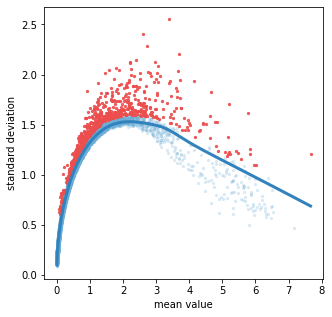

In [14]:
filter_and_select_week(week_data)  # Also saves the selected-gene list.

### 12w C. Reduce dimensions

Represent each cell using fewer dimensions. Display the reduced-dimension plot.

24 cpus are being used ...


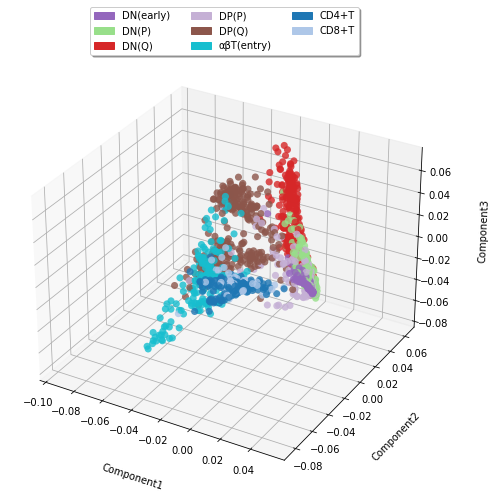

In [15]:
st.dimension_reduction(week_data['adata'])  # Use STREAM's original defaults.
save_plot(week_data['figures_dir'], '03_dimension_reduction',
          st.plot_dimension_reduction, week_data['adata'])

Developing T-cell populations form partially overlapping but distinguishable regions of transcriptional space. Such structure is compatible with the continuous differentiation landscape reported by Park et al. (2020, Fig. 2C).

### 12w D. Create the starting graph

Seed the first elastic principal graph and show its initial branches.

Seeding initial elastic principal graph...
Clustering...
Affinity propagation ...


/home/eren/miniforge3/envs/env_stream_03/lib/python3.6/site-packages/sklearn/cluster/_affinity_propagation.py:154: FutureWarning: 'random_state' has been introduced in 0.23. It will be set to None starting from 1.0 (renaming of 0.25) which means that results will differ at every function call. Set 'random_state' to None to silence this warning, or to 0 to keep the behavior of versions <0.23.
  FutureWarning


The number of initial nodes is 28
Calculatng minimum spanning tree...
Number of initial branches: 12


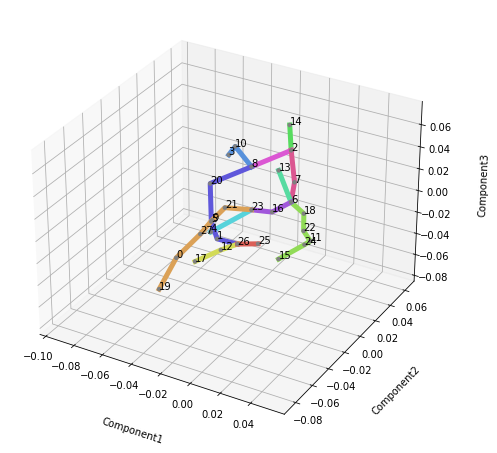

In [16]:
st.seed_elastic_principal_graph(week_data['adata'])  # Build the initial tree.
save_plot(week_data['figures_dir'], '04_seed_branches',
          st.plot_branches, week_data['adata'])

### 12w E. Fit the graph

Fit the principal graph to the cells, then show the tree with and without cells.

epg_n_nodes is too small. It is corrected to the initial number of nodes plus incr_n_nodes
Learning elastic principal graph...
[1] "Constructing tree 1 of 1 / Subset 1 of 1"
[1] "Computing EPG with 58 nodes on 1650 points and 3 dimensions"
[1] "Using a single core"
Nodes = 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47 48 49 50 51 52 53 54 55 56 57 
BARCODE	ENERGY	NNODES	NEDGES	NRIBS	NSTARS	NRAYS	NRAYS2	MSE	MSEP	FVE	FVEP	UE	UR	URN	URN2	URSD
3||58	0.0001437	58	57	50	3	0	0	8.844e-05	8.622e-05	0.9514	0.9526	4.802e-05	7.253e-06	0.0004207	0.0244	0
16.285 sec elapsed
[[1]]

Number of branches after learning elastic principal graph: 7


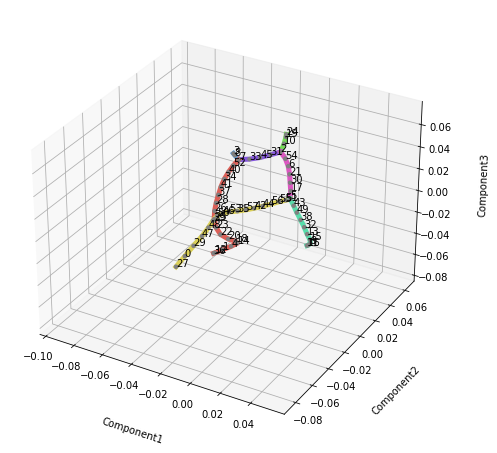

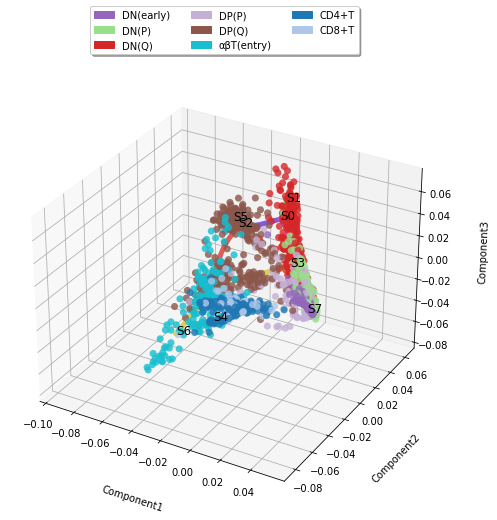

In [17]:
st.elastic_principal_graph(week_data['adata'])  # Fit branches to cell positions.
save_plot(week_data['figures_dir'], '05_fitted_branches',
          st.plot_branches, week_data['adata'])
save_plot(week_data['figures_dir'], '06_fitted_branches_cells',
          st.plot_branches_with_cells, week_data['adata'])

### 12w F. Optimize branching

Improve the branch structure and show where the cells fall along it.

Optimizing branching...
[1] "Constructing tree 1 of 1 / Subset 1 of 1"
[1] "Computing EPG with 88 nodes on 1650 points and 3 dimensions"
[1] "Using a single core"
Nodes = 58 59 60 61 62 63 64 65 66 67 68 69 70 71 72 73 74 75 76 77 78 79 80 81 82 83 84 85 86 87 
BARCODE	ENERGY	NNODES	NEDGES	NRIBS	NSTARS	NRAYS	NRAYS2	MSE	MSEP	FVE	FVEP	UE	UR	URN	URN2	URSD
3||88	9.445e-05	88	87	80	3	0	0	6.465e-05	6.29e-05	0.9645	0.9654	2.351e-05	6.286e-06	0.0005532	0.04868	0
5.948 sec elapsed
Number of branches after optimizing branching: 7


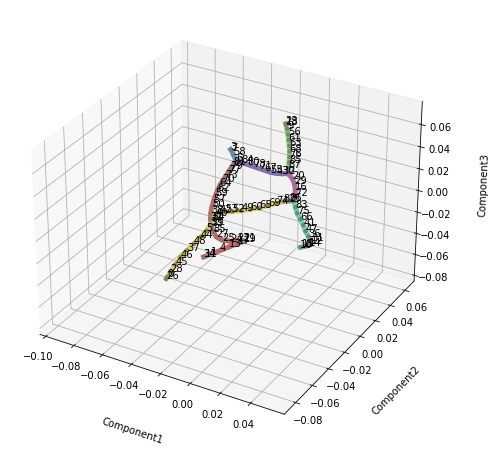

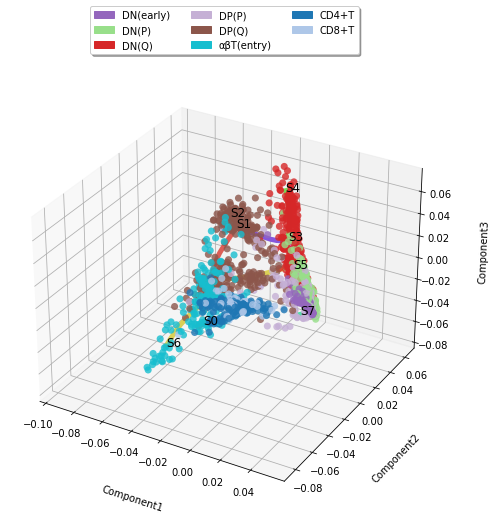

In [18]:
st.optimize_branching(week_data['adata'], reset=True)  # Refine branch arrangement.
save_plot(week_data['figures_dir'], '07_optimized_branches',
          st.plot_branches, week_data['adata'])
save_plot(week_data['figures_dir'], '08_optimized_branches_cells',
          st.plot_branches_with_cells, week_data['adata'])

### 12w G. Extend the final graph

Extend the branch endpoints using the cells. Show the extended graph and the cells on it.

Extending leaves with additional nodes ...
Number of branches after extending leaves: 7


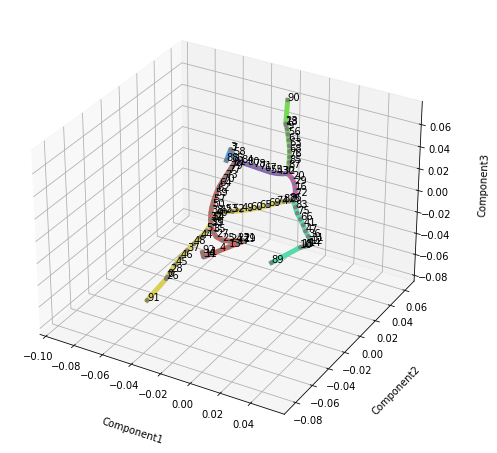

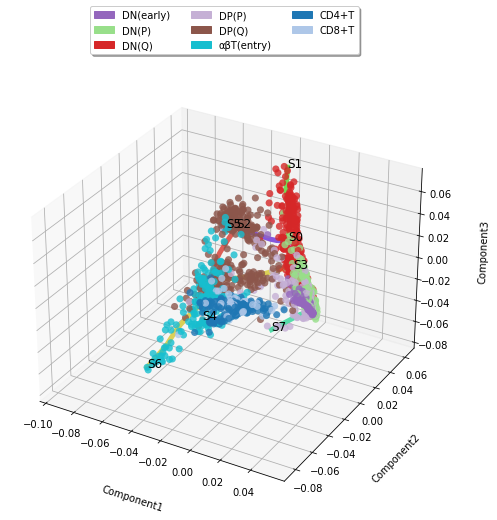

In [19]:
st.extend_elastic_principal_graph(week_data['adata'])  # Extend branch ends.
save_plot(week_data['figures_dir'], '09_extended_branches',
          st.plot_branches, week_data['adata'])
save_plot(week_data['figures_dir'], '10_extended_branches_cells',
          st.plot_branches_with_cells, week_data['adata'])

### 12w H. Identify the developmental root

Compare the states’ distances to DN(early) cells and save the fitted model before optional plotting.

In [20]:
choose_root_and_checkpoint(week_data)  # Store this week's inferred root.

Root S3 chosen from 95 DN(early) cells ONLY.
Closest candidate states for DN(early):
state  median_distance_to_DN_early  mean_distance_to_DN_early  n_DN_early_cells
   S3                     0.027315                   0.026900                95
   S0                     0.049924                   0.049033                95
   S7                     0.064903                   0.066177                95
   S2                     0.083436                   0.082162                95
   S1                     0.104235                   0.103345                95
Saved fitted-model checkpoint before downstream plots.


S3 is selected as the root from the 95 sampled DN(early) cells. This is consistent with the DN starting point in Park et al. (2020, Fig. 2), but it is **an imposed biological orientation**.

### 12w I. View the final tree and subway map

Show the simplified tree, two-dimensional cell views, and a subway plot using this week’s inferred root.

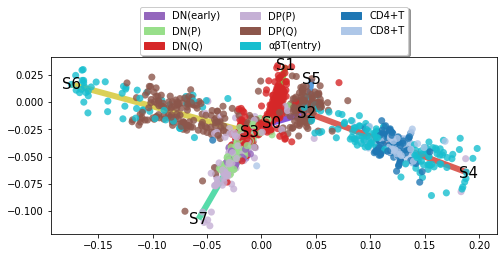

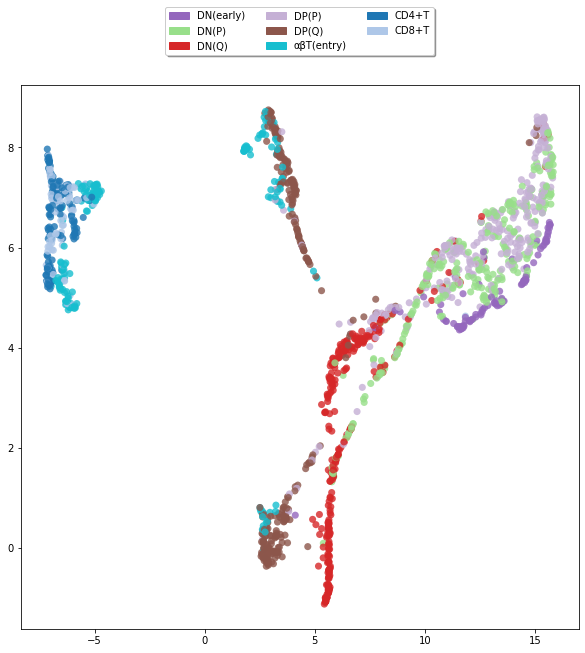

Importing precomputed umap visualization ...


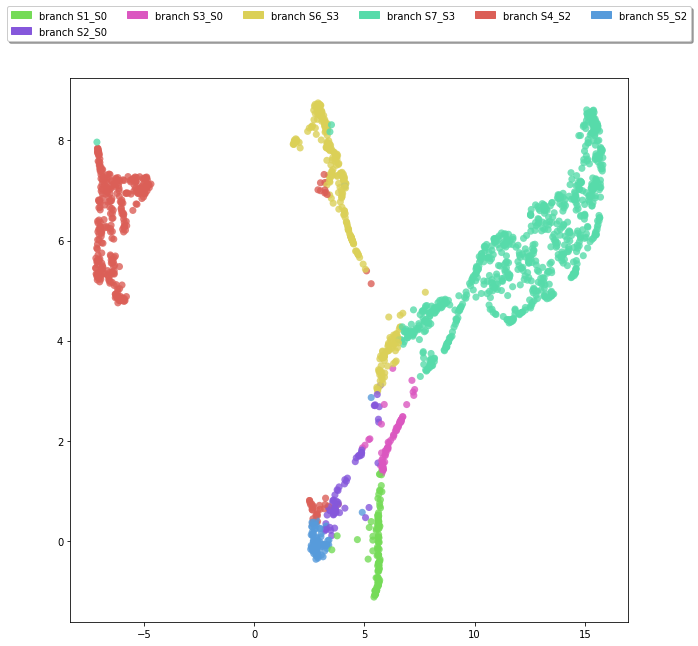

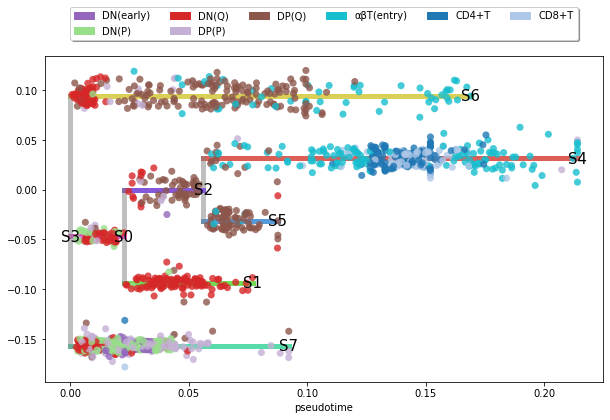

In [21]:
save_plot(week_data['figures_dir'], '11_flat_tree',
          st.plot_flat_tree, week_data['adata'])  # Simplified fitted tree.
save_plot(week_data['figures_dir'], '12_visualization_2D',
          st.plot_visualization_2D, week_data['adata'], use_precomputed=False)
save_plot(week_data['figures_dir'], '13_visualization_2D_branches',
          st.plot_visualization_2D, week_data['adata'],
          color_by='branch', fig_legend_ncol=6)
save_plot(week_data['figures_dir'], '14_subway_map',
          st.subwaymap_plot, week_data['adata'], percentile_dist=100,
          root=week_data['root'], fig_legend_ncol=6)  # Rooted subway map.

The S2–S4 branch contains αβT(entry), CD4+ and CD8+ cells, supporting part of the conventional maturation sequence (Park et al., 2020, Fig. 2C–D). However, other endpoints remain associated with immature DN/DP populations. 

### 12w J. Check T-cell marker plots

Display available T-cell markers on the fitted trajectory. Markers do not change the fit.

Available markers: ['CD34', 'CD7', 'CD1A', 'ST18', 'PTCRA', 'CDK1', 'MKI67', 'RAG1', 'RAG2', 'AQP3', 'CCR9', 'TOX2', 'CD4', 'CD8A', 'CD8B']


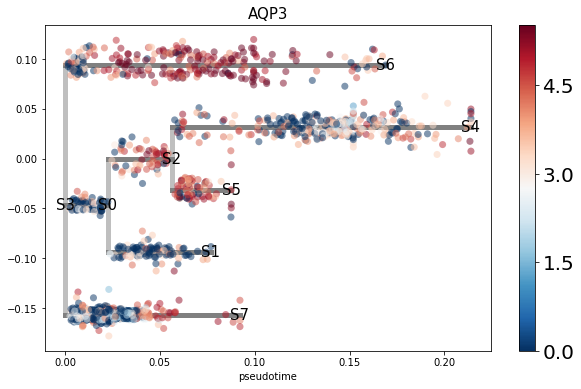

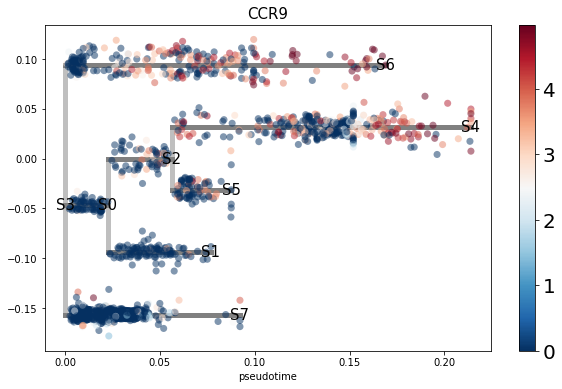

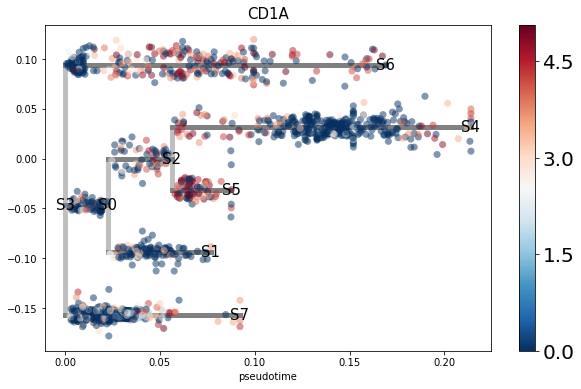

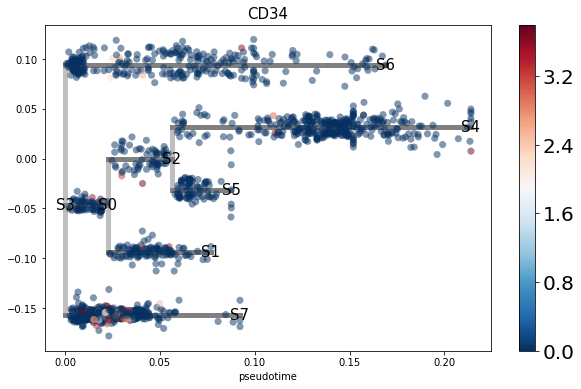

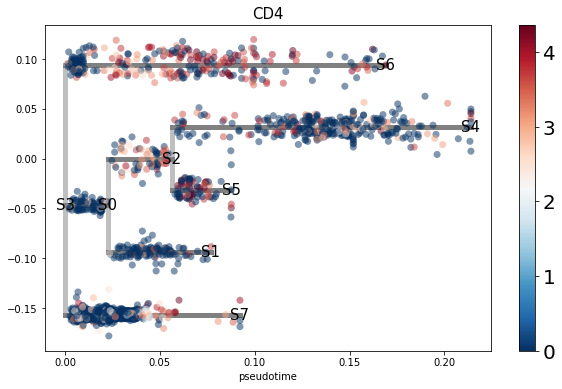

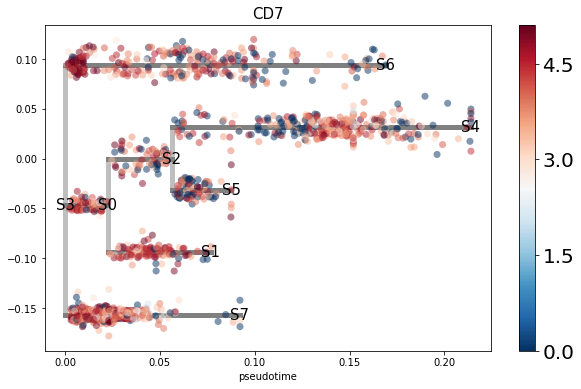

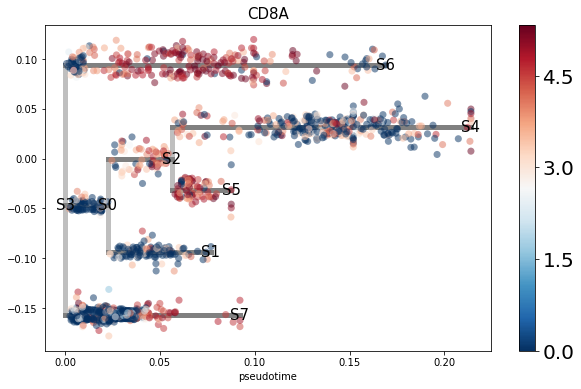

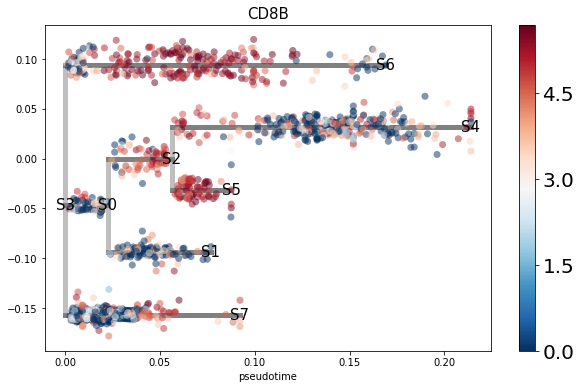

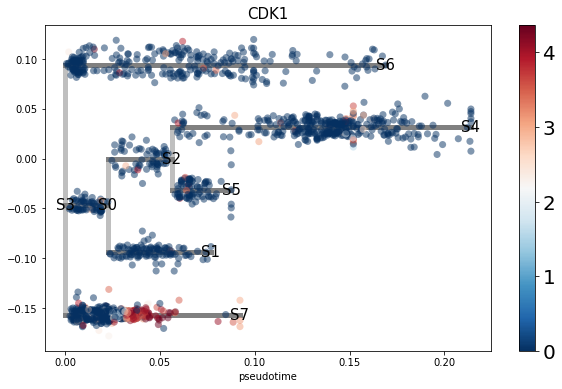

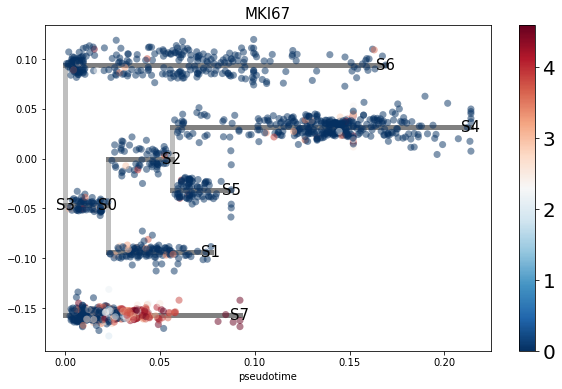

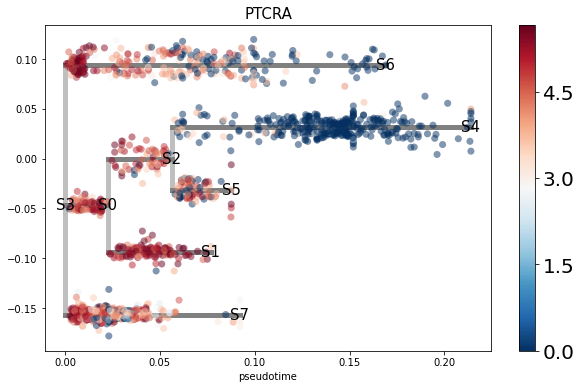

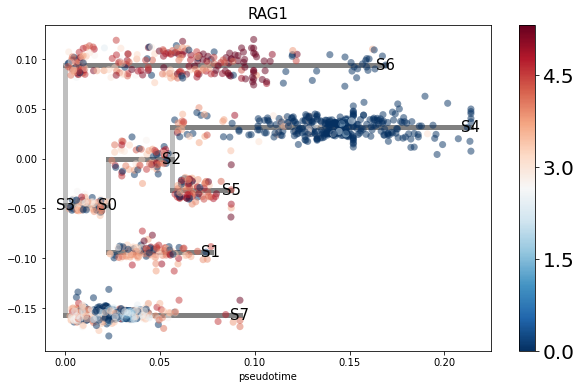

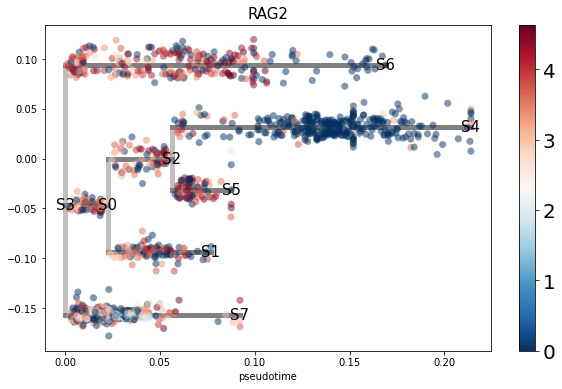

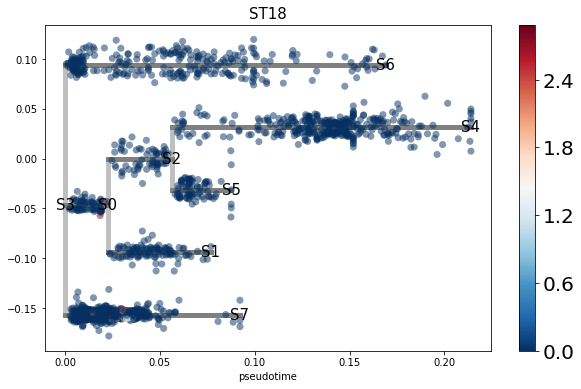

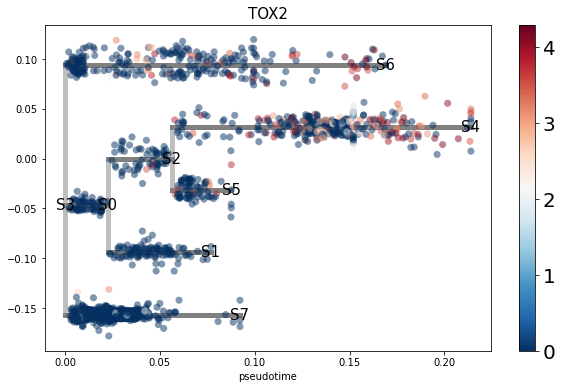

In [22]:
plot_week_markers(week_data)  # Save the marker-availability table, too.

### 12w K. Optional gene tests

By default, skip extra gene tests. Turn them on in the settings if you need them.

In [23]:
run_optional_gene_tests(week_data)  # Does nothing unless RUN_GENE_TESTS is True.

### 12w L. Export trajectories and validation figures

Export every sampled cell’s position, show pseudotime and branch-composition figures, and save marker-trend plots.


Pseudotime by annotated developmental stage:
  cell_type  developmental_order_for_diagnostic  n_cells  median_pseudotime  q25_pseudotime  q75_pseudotime
  DN(early)                                   0       95           0.027315        0.023301        0.031081
      DN(P)                                   1      290           0.026707        0.018670        0.031956
      DN(Q)                                   2      290           0.015749        0.007359        0.037990
      DP(P)                                   3      291           0.029886        0.023301        0.034843
      DP(Q)                                   4      291           0.061472        0.046584        0.072731
 αβT(entry)                                   5      181           0.122491        0.101856        0.168381
      CD4+T                                   6      126           0.140967        0.132662        0.148016
      CD8+T                                   7       86           0.145819        0.13772

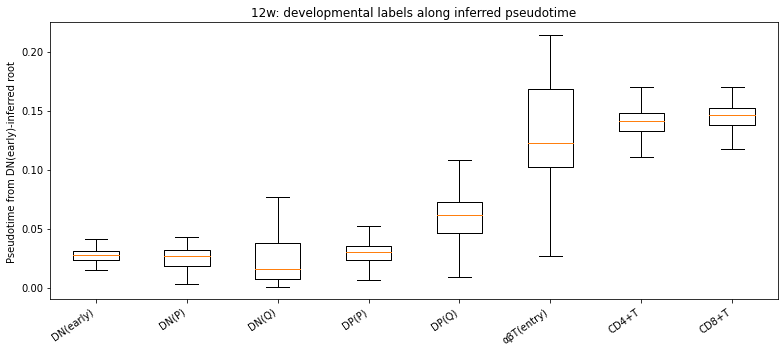

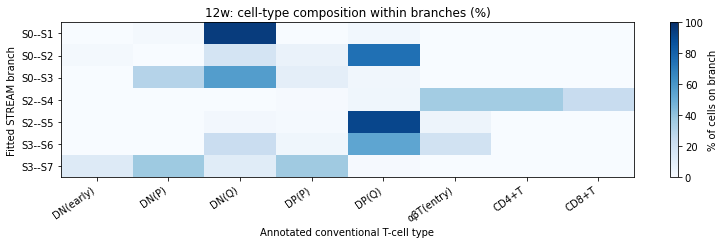

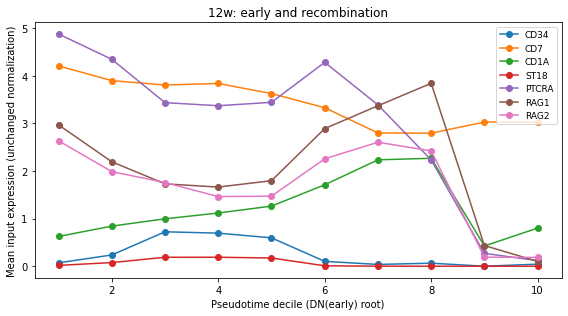

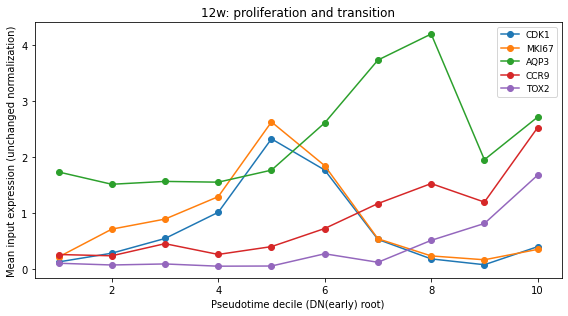

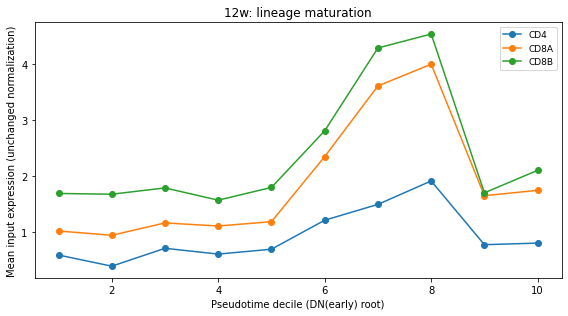

Saved 12w to /home/eren/Eren_run/Case_study_2/Results/STREAM_outputs/12w
Root: S3 | retained cells: 1650 | states: 8


90743

In [24]:
summary_12w = finish_week(week_data)  # Write all final results for 12w.
del week_data  # Free memory before continuing.
gc.collect()

Median pseudotime generally rises from DP(P) through DP(Q), αβT(entry) and SP cells, but DN(Q) has an **earlier** median than DN(early)/DN(P), so the complete early-stage order is not recovered. The S2–S4 branch includes αβT(entry) (35.6%), CD4+ (35.6%) and CD8+ (24.2%) cells. In contrast, S0–S1 is 95.1% DN(Q) and S2–S5 is 91.2% DP(Q). The mature CD4+ and CD8+ populations also share S2–S4, so a distinct CD4-versus-CD8 fate bifurcation is not clearly resolved. T

---

## 8. 17w: build an independent STREAM trajectory

The 17w fit has its own sampled cells, graph, root, figures, tables, and saved model. Follow each step in order; its plots will appear immediately under the corresponding code cell.

### 17w A. Read and sample cells

Load the prepared expression and annotations, keep only conventional T-cell types, and sample 1,650 cells.

In [25]:
week_data = prepare_week('17w')


========================  17w  ========================
Reading: /home/eren/Eren_run/Case_study_2/Results/Data_prep_outputs/17w_expression.tsv.gz
Prepared input: (7673, 33694)
Conventional T cells before sampling: 6226 | excluded: 1447
Conventional per-type counts:
DN(early)       19
DN(P)          153
DN(Q)          253
DP(P)         1500
DP(Q)         1500
αβT(entry)     775
CD4+T         1009
CD8+T         1017
Proportional selection by cell type:
      label  original_n_cells  sampled_n_cells  original_pct  sampled_pct
      CD4+T              1009              267     16.206232    16.181818
      CD8+T              1017              269     16.334725    16.303030
      DN(P)               153               41      2.457437     2.484848
      DN(Q)               253               67      4.063604     4.060606
  DN(early)                19                5      0.305172     0.303030
      DP(P)              1500              398     24.092515    24.121212
      DP(Q)              1

### 17w B. Filter and choose variable genes

Apply the original STREAM feature-selection pipeline. See the filtering/selection plots below this cell.

Fitting STREAM on: (1650, 33694)
filter genes based on min_num_cells
after filtering out low-expressed genes: 
1650 cells, 13644 genes
No open Matplotlib figure for 01_gene_filtering.
683 variable genes are selected


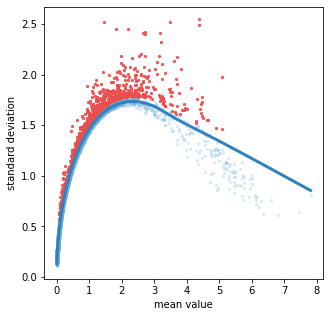

In [26]:
filter_and_select_week(week_data)  # Also saves the selected-gene list.

### 17w C. Reduce dimensions

Represent each cell using fewer dimensions. Display the reduced-dimension plot.

24 cpus are being used ...


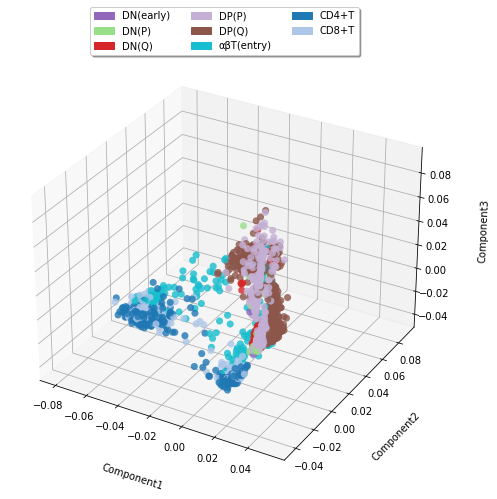

In [27]:
st.dimension_reduction(week_data['adata'])  # Use STREAM's original defaults.
save_plot(week_data['figures_dir'], '03_dimension_reduction',
          st.plot_dimension_reduction, week_data['adata'])

The 17 PCW cells occupy transcriptionally distinguishable regions, with mature and developing populations visible in the embedding. As in Park et al. (2020, Fig. 2C), nearby cells may have related expression profiles.

### 17w D. Create the starting graph

Seed the first elastic principal graph and show its initial branches.

Seeding initial elastic principal graph...
Clustering...
Affinity propagation ...


/home/eren/miniforge3/envs/env_stream_03/lib/python3.6/site-packages/sklearn/cluster/_affinity_propagation.py:154: FutureWarning: 'random_state' has been introduced in 0.23. It will be set to None starting from 1.0 (renaming of 0.25) which means that results will differ at every function call. Set 'random_state' to None to silence this warning, or to 0 to keep the behavior of versions <0.23.
  FutureWarning


The number of initial nodes is 26
Calculatng minimum spanning tree...
Number of initial branches: 11


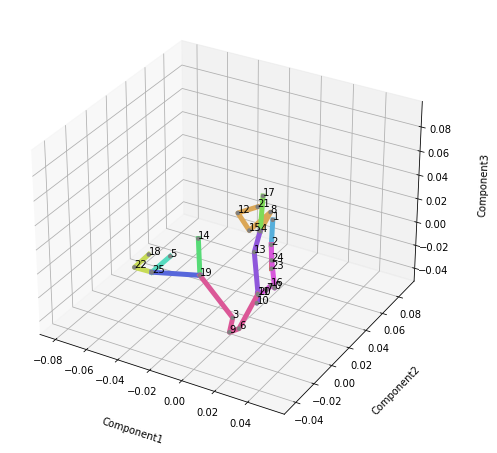

In [28]:
st.seed_elastic_principal_graph(week_data['adata'])  # Build the initial tree.
save_plot(week_data['figures_dir'], '04_seed_branches',
          st.plot_branches, week_data['adata'])

### 17w E. Fit the graph

Fit the principal graph to the cells, then show the tree with and without cells.

epg_n_nodes is too small. It is corrected to the initial number of nodes plus incr_n_nodes
Learning elastic principal graph...
[1] "Constructing tree 1 of 1 / Subset 1 of 1"
[1] "Computing EPG with 56 nodes on 1650 points and 3 dimensions"
[1] "Using a single core"
Nodes = 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47 48 49 50 51 52 53 54 55 
BARCODE	ENERGY	NNODES	NEDGES	NRIBS	NSTARS	NRAYS	NRAYS2	MSE	MSEP	FVE	FVEP	UE	UR	URN	URN2	URSD
2||56	0.0001267	56	55	50	2	0	0	7.15e-05	6.887e-05	0.9607	0.9621	4.922e-05	5.975e-06	0.0003346	0.01874	0
22.155 sec elapsed
[[1]]

Number of branches after learning elastic principal graph: 5


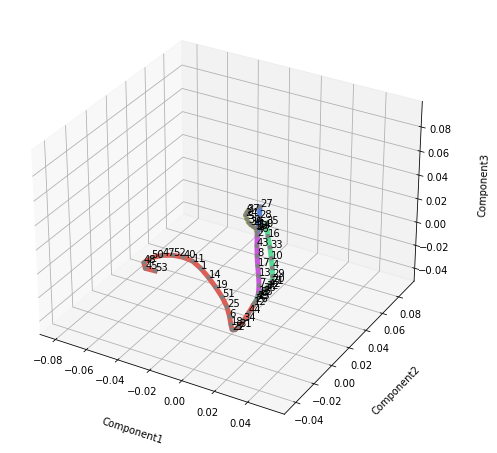

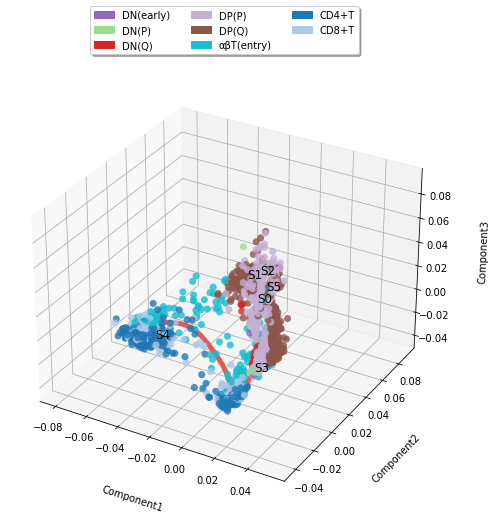

In [29]:
st.elastic_principal_graph(week_data['adata'])  # Fit branches to cell positions.
save_plot(week_data['figures_dir'], '05_fitted_branches',
          st.plot_branches, week_data['adata'])
save_plot(week_data['figures_dir'], '06_fitted_branches_cells',
          st.plot_branches_with_cells, week_data['adata'])

### 17w F. Optimize branching

Improve the branch structure and show where the cells fall along it.

Optimizing branching...
[1] "Constructing tree 1 of 1 / Subset 1 of 1"
[1] "Computing EPG with 86 nodes on 1650 points and 3 dimensions"
[1] "Using a single core"
Nodes = 56 57 58 59 60 61 62 63 64 65 66 67 68 69 70 71 72 73 74 75 76 77 78 79 80 81 82 83 84 85 
BARCODE	ENERGY	NNODES	NEDGES	NRIBS	NSTARS	NRAYS	NRAYS2	MSE	MSEP	FVE	FVEP	UE	UR	URN	URN2	URSD
2||86	8.256e-05	86	85	80	2	0	0	5.319e-05	5.125e-05	0.9708	0.9718	2.319e-05	6.176e-06	0.0005312	0.04568	0
4.99 sec elapsed
Number of branches after optimizing branching: 5


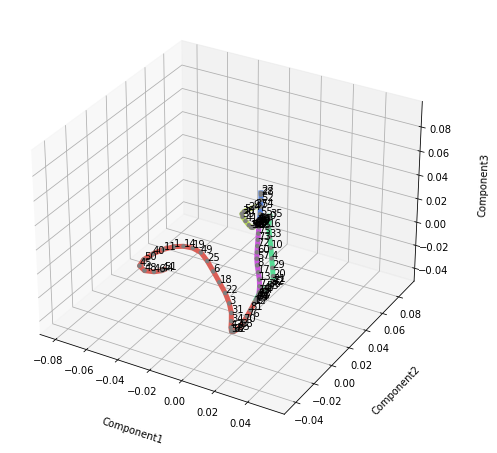

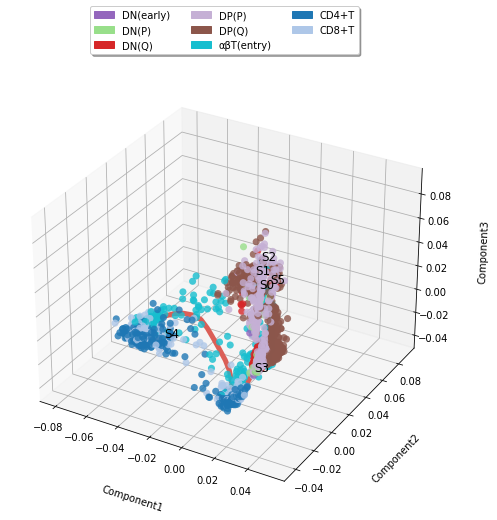

In [30]:
st.optimize_branching(week_data['adata'], reset=True)  # Refine branch arrangement.
save_plot(week_data['figures_dir'], '07_optimized_branches',
          st.plot_branches, week_data['adata'])
save_plot(week_data['figures_dir'], '08_optimized_branches_cells',
          st.plot_branches_with_cells, week_data['adata'])

### 17w G. Extend the final graph

Extend the branch endpoints using the cells. Show the extended graph and the cells on it.

Extending leaves with additional nodes ...
Number of branches after extending leaves: 5


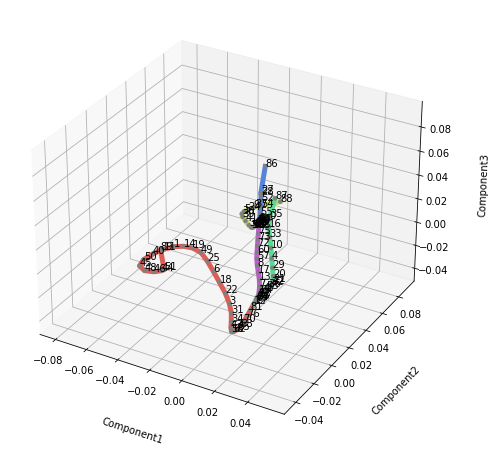

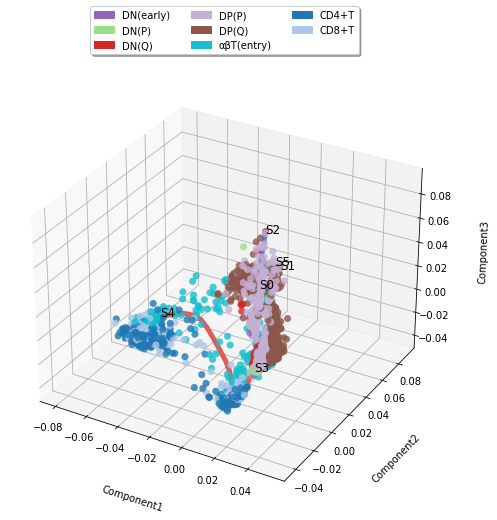

In [31]:
st.extend_elastic_principal_graph(week_data['adata'])  # Extend branch ends.
save_plot(week_data['figures_dir'], '09_extended_branches',
          st.plot_branches, week_data['adata'])
save_plot(week_data['figures_dir'], '10_extended_branches_cells',
          st.plot_branches_with_cells, week_data['adata'])

### 17w H. Identify the developmental root

Compare the states’ distances to DN(early) cells and save the fitted model before optional plotting.

In [32]:
choose_root_and_checkpoint(week_data)  # Store this week's inferred root.

Root S3 chosen from 5 DN(early) cells ONLY.
Closest candidate states for DN(early):
state  median_distance_to_DN_early  mean_distance_to_DN_early  n_DN_early_cells
   S3                     0.003748                   0.011096                 5
   S0                     0.063462                   0.057962                 5
   S2                     0.104334                   0.098834                 5
   S5                     0.114580                   0.121927                 5
   S1                     0.151295                   0.145795                 5
Saved fitted-model checkpoint before downstream plots.


S3 is selected from only **five DN(early) cells**, versus 95 for the 12 PCW root. Park et al. (2020, Fig. 2) places DN thymocytes early in the conventional trajectory, but this very small root-defining group makes the 17 PCW orientation and pseudotime particularly sensitive to sampling. 

### 17w I. View the final tree and subway map

Show the simplified tree, two-dimensional cell views, and a subway plot using this week’s inferred root.

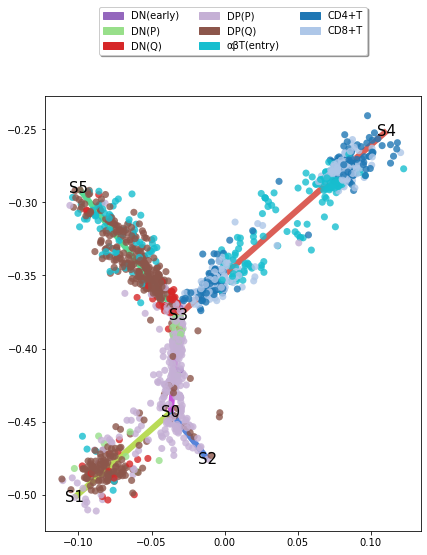

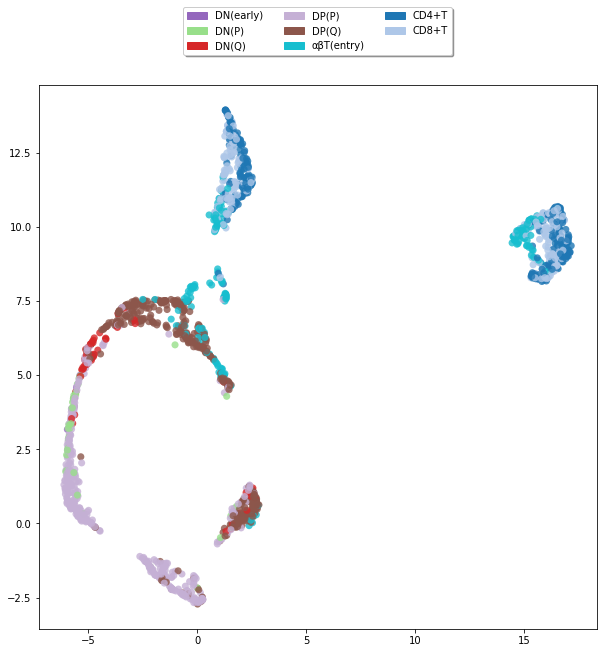

Importing precomputed umap visualization ...


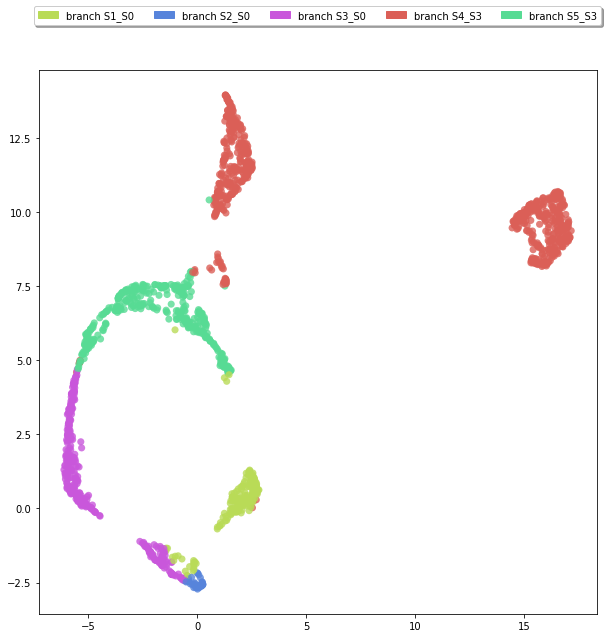

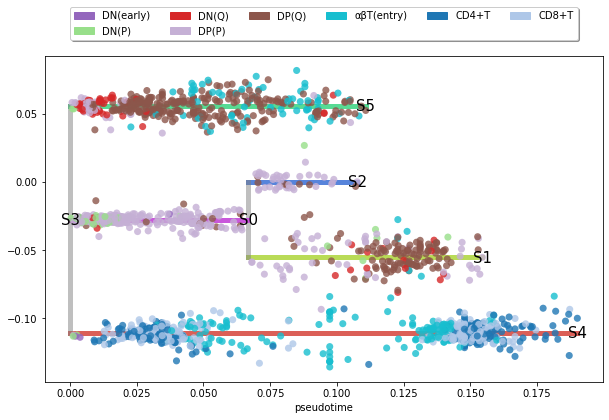

In [33]:
save_plot(week_data['figures_dir'], '11_flat_tree',
          st.plot_flat_tree, week_data['adata'])  # Simplified fitted tree.
save_plot(week_data['figures_dir'], '12_visualization_2D',
          st.plot_visualization_2D, week_data['adata'], use_precomputed=False)
save_plot(week_data['figures_dir'], '13_visualization_2D_branches',
          st.plot_visualization_2D, week_data['adata'],
          color_by='branch', fig_legend_ncol=6)
save_plot(week_data['figures_dir'], '14_subway_map',
          st.subwaymap_plot, week_data['adata'], percentile_dist=100,
          root=week_data['root'], fig_legend_ncol=6)  # Rooted subway map.

The S3–S4 branch is enriched for αβT(entry), CD4+ and CD8+ populations, consistent with later conventional αβ differentiation (Park et al., 2020, Fig. 2C–D). Other endpoints, including branches toward S1 and S2, are dominated by DP cells. 

### 17w J. Check T-cell marker plots

Display available T-cell markers on the fitted trajectory. Markers do not change the fit.

Available markers: ['CD34', 'CD7', 'CD1A', 'ST18', 'PTCRA', 'CDK1', 'MKI67', 'RAG1', 'RAG2', 'AQP3', 'CCR9', 'TOX2', 'CD4', 'CD8A', 'CD8B']


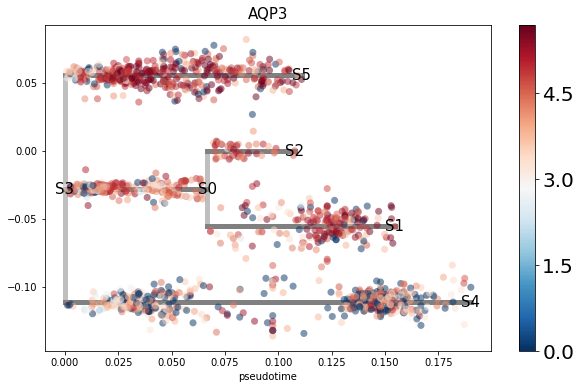

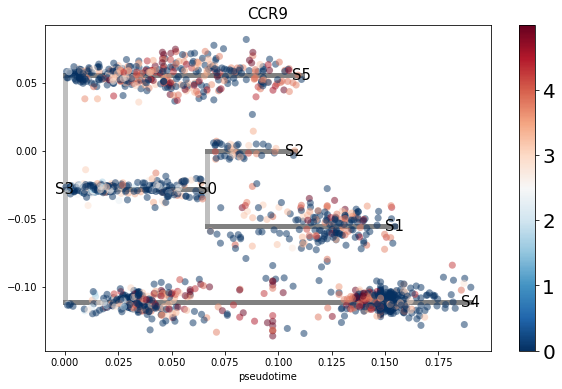

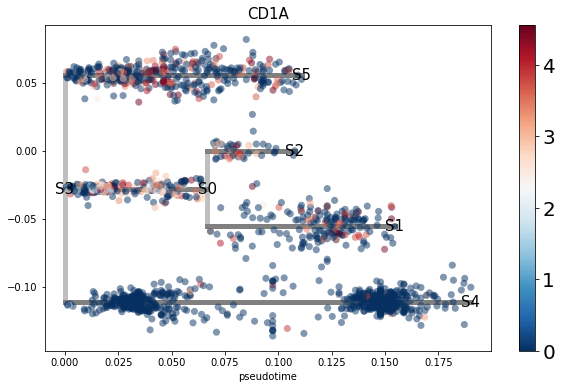

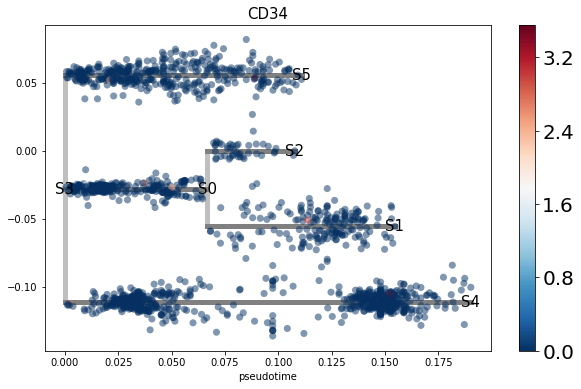

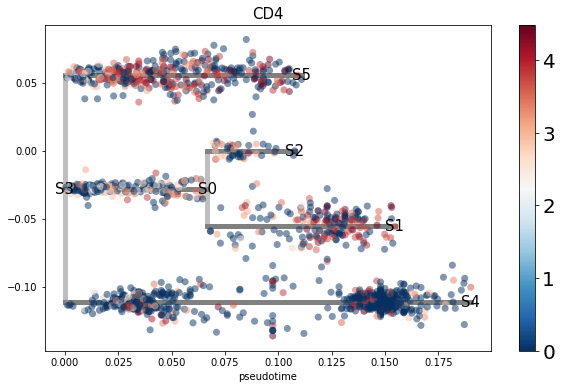

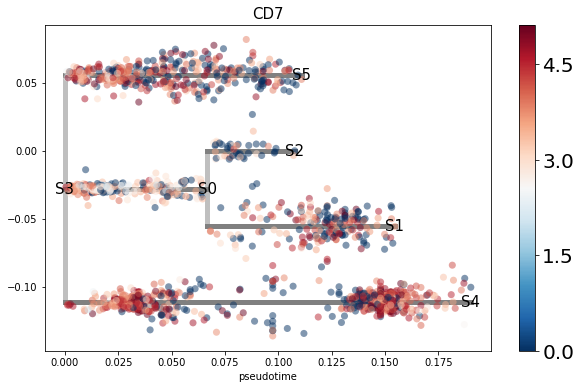

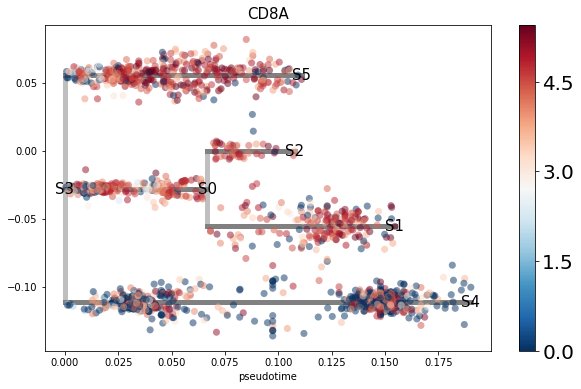

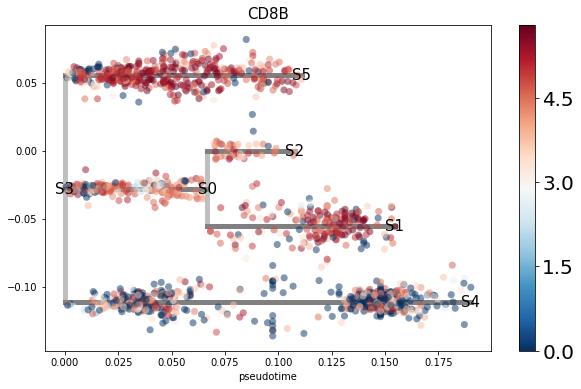

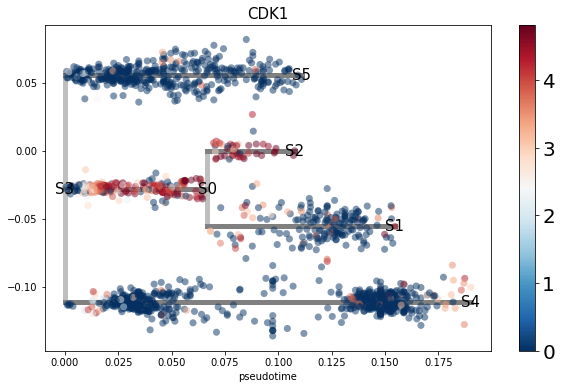

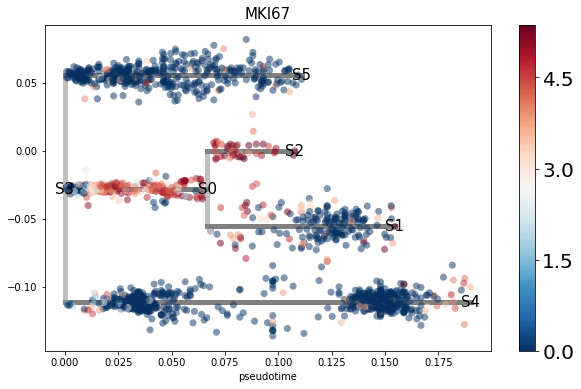

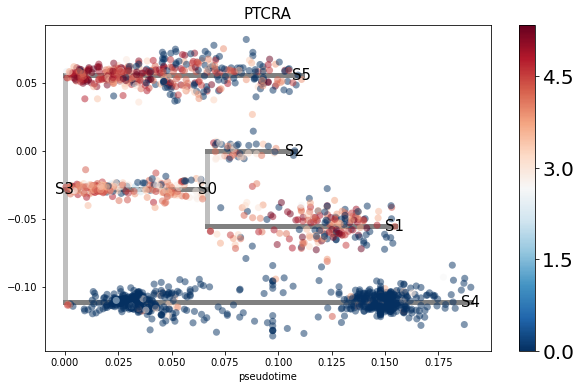

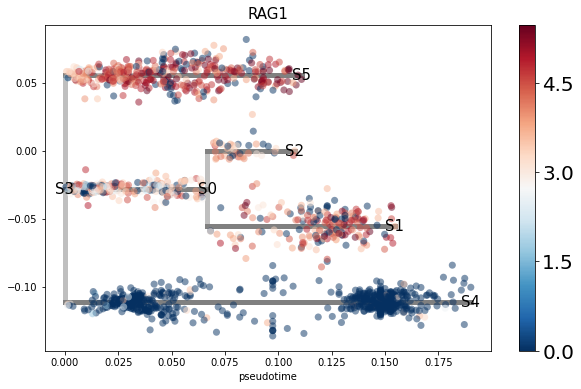

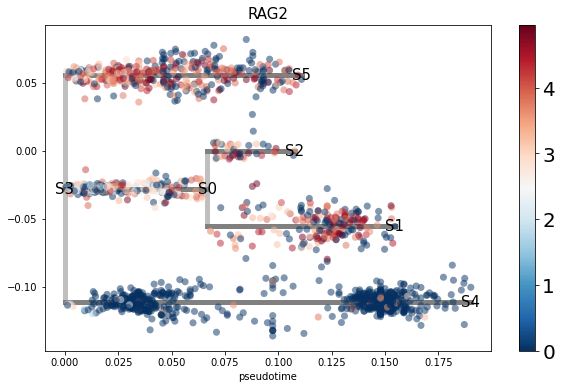

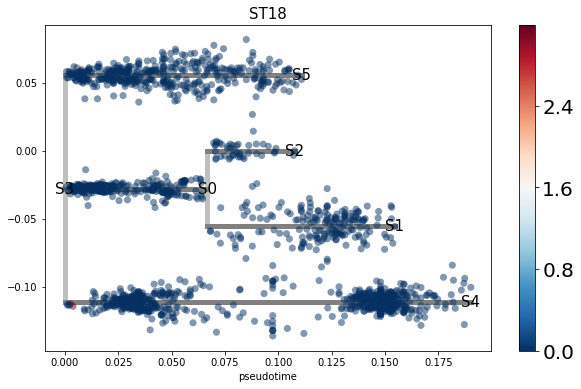

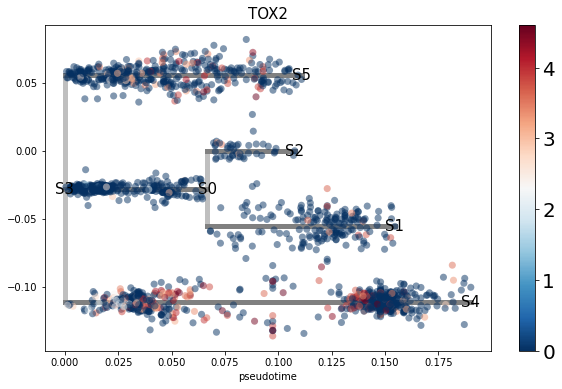

In [34]:
plot_week_markers(week_data)  # Save the marker-availability table, too.

### 17w K. Optional gene tests

By default, skip extra gene tests. Turn them on in the settings if you need them.

In [35]:
run_optional_gene_tests(week_data)  # Does nothing unless RUN_GENE_TESTS is True.

### 17w L. Export trajectories and validation figures

Export every sampled cell’s position, show pseudotime and branch-composition figures, and save marker-trend plots.


Pseudotime by annotated developmental stage:
  cell_type  developmental_order_for_diagnostic  n_cells  median_pseudotime  q25_pseudotime  q75_pseudotime
  DN(early)                                   0        5           0.003748        0.003285        0.009116
      DN(P)                                   1       41           0.010262        0.004632        0.015431
      DN(Q)                                   2       67           0.010960        0.007005        0.027851
      DP(P)                                   3      398           0.022589        0.015634        0.056696
      DP(Q)                                   4      398           0.060960        0.034041        0.113007
 αβT(entry)                                   5      205           0.090486        0.057202        0.133336
      CD4+T                                   6      267           0.144473        0.032124        0.152664
      CD8+T                                   7      269           0.081824        0.03261

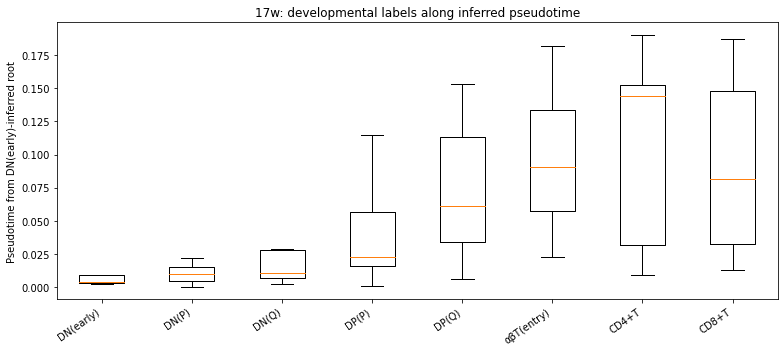

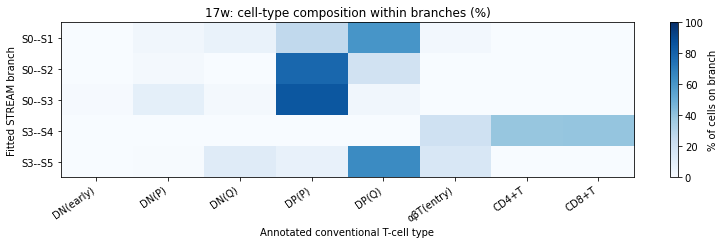

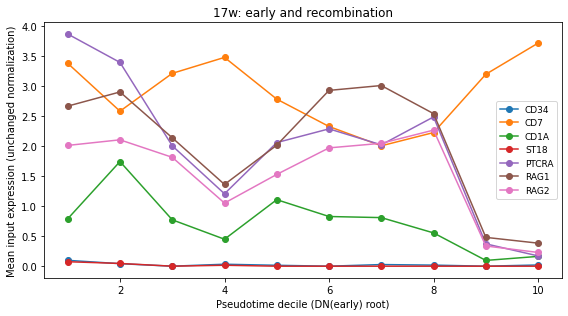

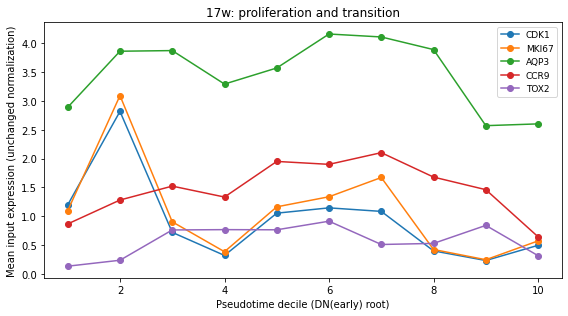

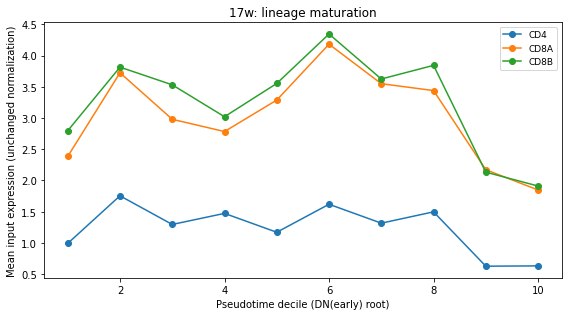

Saved 17w to /home/eren/Eren_run/Case_study_2/Results/STREAM_outputs/17w
Root: S3 | retained cells: 1650 | states: 6


84884

In [36]:
summary_17w = finish_week(week_data)  # Write all final results for 17w.
del week_data  # Free memory before continuing.
gc.collect()

Early-to-intermediate median pseudotime follows DN → DP(P) → DP(Q) → αβT(entry), and CD4+ has a later median. However, **CD8+ median pseudotime (0.082) is below αβT(entry) (0.090)**. S3–S4 is 78.9% CD4+/CD8+ combined, while S0–S1 is 60.8% DP(Q), S0–S2 is 78.7% DP(P), and S3–S5 is 65.0% DP(Q). CD4+ and CD8+ cells share S3–S4 rather than forming clearly separate terminal branches. Leaves may indicate intermediate heterogeneity or excess branching, not stable terminal fates. 

## 9. Combined summary

Read the two independent run summaries from disk. This creates a single overview **without merging their trajectories**.

In [37]:
# Read completed per-week summaries from disk; neither week depends on the other's variables.
completed = []
for week in WEEKS:
    path = OUTPUT_ROOT / week / 'run_summary.json'
    if path.exists():
        with path.open(encoding='utf-8') as handle:
            completed.append(json.load(handle))
if completed:
    manifest = pd.DataFrame(completed)
    manifest.to_csv(OUTPUT_ROOT / 'weekly_run_summary.csv', index=False)
    print(manifest[['week', 'selected_t_cells', 'root', 'n_branches']].to_string(index=False))
else:
    print('No completed STREAM runs found yet.')

week  selected_t_cells root  n_branches
 12w              1650   S3           7
 17w              1650   S3           5


## 10. Output files

Each week saves the same file types independently under `../Results/STREAM_outputs/12w/` and `../Results/STREAM_outputs/17w/`.

- `figures/`: STREAM plots and post-fit biological-validation plots, also shown inline when executed.
- `tables/cell_type_selection.csv`, `cell_type_sampling.csv`, `sampled_cell_ids.csv`: which cells were included and sampled.
- `tables/selected_stream_variable_genes.csv`, `marker_availability.csv`: feature-selection and marker records.
- `tables/root_candidate_scores.csv`: DN(early)-only root evaluation.
- `tables/all_cells_trajectory.csv`, `all_cells_distances_long.csv`: one row per sampled cell, and one row per cell–state pair.
- `tables/tree_nodes.csv`, `tree_edges.csv`, `state_cell_type_counts.csv`: graph and state composition.
- `tables/pseudotime_by_cell_type.csv`, `branch_cell_type_counts.csv`, the percentage tables, and `biological_validation_summary.json`: descriptive validation.
- `tables/marker_expression_per_cell.csv`, `marker_means_by_pseudotime_decile.csv`: available marker-expression data.
- `stream_result.pkl`, `run_summary.json`: fitted model and summary.

`../Results/STREAM_outputs/weekly_run_summary.csv` holds the combined run overview. **State IDs and pseudotime scales are not directly comparable between independently fitted weeks.**

### List saved results

Print the exported file paths to check what was created after both weeks have run.

In [38]:
for week in WEEKS:
    output = OUTPUT_ROOT / week
    print(f'\n{week}: {output.resolve()}')
    if output.is_dir():
        for p in sorted(output.rglob('*')):
            if p.is_file():
                print('  ', p.relative_to(output))


12w: /home/eren/Eren_run/Case_study_2/Results/STREAM_outputs/12w
   figures/02_variable_genes - Copy.png:Zone.Identifier
   figures/02_variable_genes.png
   figures/03_dimension_reduction - Copy.png:Zone.Identifier
   figures/03_dimension_reduction.png
   figures/04_seed_branches - Copy.png:Zone.Identifier
   figures/04_seed_branches.png
   figures/05_fitted_branches - Copy.png:Zone.Identifier
   figures/05_fitted_branches.png
   figures/06_fitted_branches_cells - Copy.png:Zone.Identifier
   figures/06_fitted_branches_cells.png
   figures/07_optimized_branches.png
   figures/08_optimized_branches_cells.png
   figures/09_extended_branches - Copy.png:Zone.Identifier
   figures/09_extended_branches.png
   figures/10_extended_branches_cells - Copy.png:Zone.Identifier
   figures/10_extended_branches_cells.png
   figures/11_flat_tree - Copy.png:Zone.Identifier
   figures/11_flat_tree.png
   figures/12_visualization_2D - Copy.png:Zone.Identifier
   figures/12_visualization_2D.png
   figures/